# 🐱🐶 Cat vs Dog Image Classification — End-to-End Capstone

**From raw images → data audit → cleaning → traditional ML → feature engineering → CNN → augmentation → transfer learning → evaluation → deployment**

This single notebook answers **all 50 questions** of the capstone task sheet, in order, and produces the deliverables listed in the project brief (cleaned data, split files, trained models, model-comparison table, reusable `src/` modules, Streamlit app, README and `requirements.txt`).

| Phase | Questions | What happens |
|---|---|---|
| 1 | Q1–Q5 | Problem understanding |
| 2 | Q6–Q15 | Dataset acquisition, scan, EDA |
| 3 | Q16–Q21 | Corruption, duplicates, anomalies, channels, cleaned dataset |
| 4 | Q22–Q29 | Resize, normalise, encode, stratified split, leakage |
| 5 | Q30–Q37 | Raw-pixel ML baselines (LR, KNN, SVM, RF) |
| 6 | Q38–Q42 | Grayscale, HOG, PCA |
| 7 | Q43–Q46 | Custom CNNs |
| 8 | Q47–Q49 | Augmentation, transfer learning, full evaluation, error analysis |
| 9 | Q50 | Saved model + Streamlit app + README |

### How to run (Google Colab)
1. **Runtime → Change runtime type → T4 GPU.**
2. Run cells top to bottom. The notebook mounts Drive, looks for `Cats and Dogs Dataset for Image Classification.zip`, and falls back to `gdown` if it is not found.
3. **Tip:** if the shared link hits Google's download quota, open the link in your browser → *Add a shortcut / Make a copy* into **My Drive**, then re-run the data cell.
4. Set `FAST_DEBUG = True` in the config cell for a 5-minute dry run on a tiny subset, then set it back to `False` for the real run (full run ≈ 45–75 min on a T4).

### Design rules followed (from the project brief)
* The **test set is never touched** until model selection is finished (all model selection uses the validation set).
* Fixed random seed everywhere; splits are saved to disk.
* Scalers / PCA are **fit on training data only**; augmentation is applied to **training data only**.
* Models are compared on **Accuracy, Precision, Recall, F1, ROC-AUC, confusion matrices, training time, inference time and model size** — not accuracy alone.
* Reusable code lives in `src/*.py` (written by this notebook with `%%writefile`) and is imported back, so the notebook and the deployed app use *exactly* the same preprocessing.

In [ ]:
%pip install -q scikit-image gdown openpyxl tqdm

In [ ]:
import os, sys, json, time, random, re, shutil, zipfile, warnings, importlib, inspect, platform, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from PIL import Image

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

def md(text):
    display(Markdown(text))

# ───────────────────────────── switches & hyper-parameters ─────────────────────────────
FAST_DEBUG = False        # True → tiny dry run (few images, 1 epoch) just to verify the pipeline
FAST_DEBUG = FAST_DEBUG or os.environ.get("FAST_DEBUG") == "1"
PRETRAINED = os.environ.get("NO_PRETRAINED") != "1"   # keep True on Colab (downloads ImageNet weights)

SEED            = 42
ML_IMG          = 64      # flattened-pixel / HOG / PCA experiments
CNN_IMG         = 128     # custom CNNs
TL_IMG          = 224     # MobileNetV2 transfer learning
CLEAN_MAX_SIDE  = 256     # cleaned images are RGB JPEGs with longest side capped at this value
MIN_SIDE        = 32      # images with a shorter side than this are removed as uninformative
REMOVE_NEAR_DUPLICATES = True
SPLIT           = dict(train=0.70, val=0.15, test=0.15)

BATCH           = 64
EPOCHS_CNN      = 15
EPOCHS_AUG      = 25
EPOCHS_TL_HEAD  = 5
EPOCHS_TL_FT    = 5
ML_TRAIN_PER_CLASS = 2500   # traditional-ML experiments use a tractable subset of the TRAIN split
ML_VAL_PER_CLASS   = 600
DEBUG_LIMIT     = None      # max images per class scanned (None = all)

if FAST_DEBUG:
    EPOCHS_CNN = EPOCHS_AUG = EPOCHS_TL_HEAD = EPOCHS_TL_FT = 1
    ML_TRAIN_PER_CLASS, ML_VAL_PER_CLASS = 60, 20
    DEBUG_LIMIT = int(os.environ.get("DEBUG_LIMIT", 300))
    BATCH = 32

# ───────────────────────────────────── paths ─────────────────────────────────────
IN_COLAB = "google.colab" in sys.modules
SUFFIX = "_debug" if FAST_DEBUG else ""
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT  = Path("/content/drive/MyDrive")
    PROJECT_DIR = Path(os.environ.get("PROJECT_DIR", DRIVE_ROOT / "Cat-Dog-Classification"))
    DATA_DIR    = Path("/content/data")           # big image folders on fast local disk
else:
    DRIVE_ROOT  = None
    PROJECT_DIR = Path(os.environ.get("PROJECT_DIR", "./Cat-Dog-Classification")).resolve()
    DATA_DIR    = PROJECT_DIR / "data"

RAW_DIR     = DATA_DIR / "raw"
CLEAN_DIR   = DATA_DIR / f"cleaned{SUFFIX}"
PROC_DIR    = DATA_DIR / f"processed{SUFFIX}"
MODELS_DIR  = PROJECT_DIR / f"models{SUFFIX}"
REPORTS_DIR = PROJECT_DIR / f"reports{SUFFIX}"
LOGS_DIR    = REPORTS_DIR / "logs"
SRC_DIR     = PROJECT_DIR / "src"
APP_DIR     = PROJECT_DIR / "app"
for d in [RAW_DIR, CLEAN_DIR, PROC_DIR, MODELS_DIR, REPORTS_DIR, LOGS_DIR, SRC_DIR, APP_DIR]:
    d.mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT_DIR)
sys.path.insert(0, str(PROJECT_DIR))

random.seed(SEED); np.random.seed(SEED)
print("Project dir :", PROJECT_DIR)
print("Data dir    :", DATA_DIR)
print("FAST_DEBUG  :", FAST_DEBUG, "| Colab:", IN_COLAB, "| Python", platform.python_version())

Mounted at /content/drive
Project dir : /content/drive/MyDrive/Cat-Dog-Classification
Data dir    : /content/data
FAST_DEBUG  : False | Colab: True | Python 3.13.16


---
# Phase 1 — Problem Understanding & Dataset Exploration

### Q1. What is the objective of the project? Define the ML problem.
The objective is to build a complete, reproducible image-classification solution that, given a photograph, predicts whether it contains a **cat** or a **dog**, and to deploy it as a small web application. Formally: learn a function $f_\theta : \mathbb{R}^{H\times W\times 3} \to [0,1]$ from labelled examples $(x_i, y_i)$ so that $f_\theta(x)$ estimates $P(\text{Dog}\mid x)$; the predicted class is Dog if $f_\theta(x)\ge 0.5$, otherwise Cat. The goal is to minimise error on **unseen** images, which is why train / validation / test splits, regularisation and honest evaluation are central.

### Q2. Supervised, unsupervised or reinforcement learning?
**Supervised learning.** Every training image comes with a ground-truth label (the folder name *Cat* or *Dog*) and the model learns the mapping image → label by minimising a loss against those labels. It is not unsupervised (no label-free structure discovery) and not reinforcement learning (no agent, environment or reward signal).

### Q3. Binary or multiclass?
**Binary classification** — there are exactly two mutually exclusive classes. This is why the CNN ends with **one sigmoid unit** trained with binary cross-entropy (rather than a softmax over several units), and why precision / recall / ROC-AUC are defined with respect to a single positive class (we use *Dog = 1*).

### Q4. Independent and dependent variables
* **Independent variables (features, X):** the pixel intensities of the image — an $H\times W\times 3$ array (e.g. 64×64×3 = 12,288 numbers for the classical models, 128×128×3 for the CNN), or engineered features derived from them (grayscale pixels, HOG descriptors, PCA components).
* **Dependent variable (target, y):** the class label — *Cat* (0) or *Dog* (1).

### Q5. Real-world applications
* **Pet-adoption / lost-and-found platforms** – auto-tag uploaded photos by species and flag mislabelled listings.
* **Smart pet doors and feeders** – open only for the right animal; ignore wildlife.
* **Veterinary and shelter software** – intake photo triage, inventory and record keeping.
* **Content moderation & photo-library organisation** – automatic album creation, searchable "dogs" / "cats" tags.
* **Wildlife / camera-trap monitoring and home security** – distinguish pets from other animals or intruders.
* **Education** – a gentle, intuitive way to teach computer vision (the same pipeline extends to breed or multi-species classification).

---
# Phase 2 — Dataset Acquisition & Understanding

In [ ]:
DRIVE_FILE_ID = "1_XdCm9Xupn-WMwswWx53JE0eUH0pcHGl"
ZIP_NAME = "Cats and Dogs Dataset for Image Classification.zip"

def find_dataset_zip():
    """Look for the dataset zip: env var → Drive (My Drive & common sub-folders) → local folders."""
    env = os.environ.get("DATASET_ZIP")
    if env and Path(env).exists():
        return Path(env)
    candidates = []
    if IN_COLAB:
        candidates += [DRIVE_ROOT / ZIP_NAME, DRIVE_ROOT / "Colab Notebooks" / ZIP_NAME,
                       DRIVE_ROOT / "datasets" / ZIP_NAME, PROJECT_DIR / ZIP_NAME]
        candidates += list(DRIVE_ROOT.glob("*Cats*Dogs*.zip")) + list(DRIVE_ROOT.glob("*cats*dogs*.zip"))
    candidates += [Path.cwd() / ZIP_NAME, Path("/content") / ZIP_NAME, DATA_DIR / ZIP_NAME]
    for c in candidates:
        if Path(c).exists():
            return Path(c)
    return None

def download_with_gdown():
    import gdown
    out = DATA_DIR / ZIP_NAME
    url = f"https://drive.google.com/uc?id={DRIVE_FILE_ID}"
    try:
        res = gdown.download(url, str(out), quiet=False)
    except Exception as exc:
        res = None
        print("gdown error:", exc)
    if not res or not out.exists():
        raise RuntimeError(
            "Could not download the dataset (Google Drive quota / permissions).\n"
            "Fix: open the Drive link in your browser → 'Add shortcut to Drive' or 'Make a copy' "
            "into My Drive, then re-run this cell (the notebook will find it automatically).")
    return out

def print_tree(root, max_depth=3):
    root = Path(root)
    for dirpath, dirnames, filenames in os.walk(root):
        dirnames.sort()
        depth = len(Path(dirpath).relative_to(root).parts)
        name = Path(dirpath).name if depth else root.name
        print(f"{'    ' * depth}📁 {name}/   ({len(filenames):,} files)")
        if depth >= max_depth:
            dirnames[:] = []

# ── Q6: acquire + extract + inspect directory structure ──
if next(RAW_DIR.rglob("*"), None) is None:
    zip_path = find_dataset_zip()
    if zip_path is None:
        print("Zip not found on Drive → downloading with gdown …")
        zip_path = download_with_gdown()
    print("Extracting", zip_path, "→", RAW_DIR)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(RAW_DIR)
else:
    print("Raw data already extracted at", RAW_DIR)
print_tree(RAW_DIR, max_depth=3)

Extracting /content/drive/MyDrive/Cat-Dog-Classification/Cats and Dogs Dataset for Image Classification.zip → /content/data/raw
📁 raw/   (0 files)
    📁 Cats and Dogs Classification Dataset/   (0 files)
        📁 Cat/   (12,499 files)
        📁 Dog/   (12,499 files)


In [ ]:
# ── write src/data_cleaning.py (reusable module) ──
(SRC_DIR / "__init__.py").write_text("# Cat-vs-Dog capstone: reusable modules\n")

40

In [ ]:
%%writefile src/data_cleaning.py
"""Data audit and cleaning utilities for the Cat vs Dog project."""
import hashlib
import os
import warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=UserWarning)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp", ".tif", ".tiff"}
FORMAT_TO_EXT = {"JPEG": {".jpg", ".jpeg"}, "PNG": {".png"}, "GIF": {".gif"}, "BMP": {".bmp"},
                 "WEBP": {".webp"}, "TIFF": {".tif", ".tiff"}}
JUNK_NAMES = {"thumbs.db", ".ds_store", "desktop.ini"}
CLEAN_MAX_SIDE = 256
N_WORKERS = min(32, (os.cpu_count() or 2) * 4)


# ───────────────────────────── scanning ─────────────────────────────
def is_junk(path):
    p = Path(path)
    return p.name.startswith("._") or p.name.lower() in JUNK_NAMES or "__MACOSX" in p.parts


def label_from_path(path, root):
    """Class = nearest ancestor folder whose name mentions exactly one of 'cat' / 'dog'."""
    rel = Path(path).relative_to(root)
    for part in reversed(rel.parts[:-1]):
        p = part.lower()
        has_cat, has_dog = "cat" in p, "dog" in p
        if has_cat != has_dog:
            return "Cat" if has_cat else "Dog"
    return "Unknown"


def list_files(root):
    return sorted(str(p) for p in Path(root).rglob("*") if p.is_file())


def scan_image(path):
    """Return one metadata record; never raises. A file is `valid` only if it fully decodes."""
    p = Path(path)
    rec = {"path": str(p), "extension": p.suffix.lower(), "file_size": p.stat().st_size,
           "width": np.nan, "height": np.nan, "mode": None, "channels": np.nan,
           "format": None, "valid": False, "error": ""}
    if rec["file_size"] == 0:
        rec["error"] = "EmptyFile: 0 bytes"
        return rec
    try:
        with Image.open(p) as im:
            rec.update(width=im.width, height=im.height, mode=im.mode,
                       channels=len(im.getbands()), format=im.format)
            im.verify()
        with Image.open(p) as im:      # verify() does not decode pixels → force a full decode
            im.load()
        rec["valid"] = True
    except Exception as exc:
        rec["error"] = f"{type(exc).__name__}: {exc}"[:160]
    return rec


def scan_dataset(root, workers=N_WORKERS, limit_per_class=None):
    """Recursively scan `root` → DataFrame(path, label, width, height, channels, extension, ...)."""
    root = Path(root)
    all_files = list_files(root)
    files = [f for f in all_files if not is_junk(f)]
    labels = {f: label_from_path(f, root) for f in files}
    if limit_per_class:
        kept, seen = [], {}
        for f in files:
            lab = labels[f]
            seen[lab] = seen.get(lab, 0) + 1
            if lab == "Unknown" or seen[lab] <= limit_per_class:
                kept.append(f)
        files = kept
    with ThreadPoolExecutor(workers) as ex:
        records = list(tqdm(ex.map(scan_image, files), total=len(files), desc="scanning"))
    df = pd.DataFrame(records)
    df["label"] = df["path"].map(labels)
    df["is_image_ext"] = df["extension"].isin(IMAGE_EXTENSIONS)
    exp = df["format"].map(lambda f: FORMAT_TO_EXT.get(f, set()) if f else set())
    df["ext_mismatch"] = [bool(f) and e not in s for f, e, s in zip(df["format"], df["extension"], exp)]
    df.attrs["junk_files_ignored"] = len(all_files) - len(files) if not limit_per_class else None
    return df


# ───────────────────────── corruption handling ─────────────────────────
def detect_and_record_corrupted(df, report_csv=None, quarantine_dir=None):
    """Record every unreadable file (CSV report) and optionally MOVE it to a quarantine folder."""
    import shutil
    bad = df[~df["valid"]].copy()
    if report_csv is not None:
        bad.to_csv(report_csv, index=False)
    if quarantine_dir is not None:
        for p, lab in zip(bad["path"], bad["label"]):
            dst = Path(quarantine_dir) / str(lab)
            dst.mkdir(parents=True, exist_ok=True)
            shutil.move(p, dst / Path(p).name)
    return bad


# ───────────────────────────── duplicates ─────────────────────────────
def md5_file(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def dhash(path, hash_size=16):
    """Difference hash: robust to re-encoding / mild resizing (256-bit for hash_size=16)."""
    with Image.open(path) as im:
        g = im.convert("L").resize((hash_size + 1, hash_size), Image.BILINEAR)
    a = np.asarray(g, dtype=np.int16)
    bits = (a[:, 1:] > a[:, :-1]).flatten()
    return np.packbits(bits).tobytes().hex()


def _hash_one(path):
    try:
        m = md5_file(path)
    except Exception:
        m = None
    try:
        d = dhash(path)
    except Exception:
        d = None
    return m, d


def add_hashes(df, workers=N_WORKERS):
    with ThreadPoolExecutor(workers) as ex:
        res = list(tqdm(ex.map(_hash_one, df["path"].tolist()), total=len(df), desc="hashing"))
    out = df.copy()
    out["md5"] = [r[0] for r in res]
    out["dhash"] = [r[1] for r in res]
    return out


# ─────────────────────── channel standardisation & cleaning ───────────────────────
def to_rgb(im):
    """Respect EXIF orientation and convert ANY mode (L, P, RGBA, CMYK …) to 3-channel RGB.
    Transparent pixels are composited on white instead of turning black."""
    im = ImageOps.exif_transpose(im)
    if im.mode in ("RGBA", "LA") or (im.mode == "P" and "transparency" in im.info):
        im = im.convert("RGBA")
        bg = Image.new("RGB", im.size, (255, 255, 255))
        bg.paste(im, mask=im.split()[-1])
        return bg
    return im.convert("RGB")


def cap_size(im, max_side=CLEAN_MAX_SIDE):
    """Downscale (keeping aspect ratio) so the longest side is <= max_side."""
    if max(im.size) > max_side:
        s = max_side / max(im.size)
        im = im.resize((max(1, round(im.width * s)), max(1, round(im.height * s))), Image.LANCZOS)
    return im


def standardize_image(src, max_side=CLEAN_MAX_SIDE):
    with Image.open(src) as im:
        out = cap_size(to_rgb(im), max_side)
        out.load()
    return out


def build_cleaned_dataset(df, out_dir, max_side=CLEAN_MAX_SIDE, quality=95, workers=N_WORKERS):
    """Write every row of `df` as an RGB JPEG into out_dir/<label>/ and return the manifest."""
    out_dir = Path(out_dir)
    df = df.copy().reset_index(drop=True)
    names = df["label"].str.lower() + "_" + df.groupby("label").cumcount().astype(str).str.zfill(5) + ".jpg"
    df["clean_path"] = [str(out_dir / lab / nm) for lab, nm in zip(df["label"], names)]
    for lab in df["label"].unique():
        (out_dir / lab).mkdir(parents=True, exist_ok=True)

    def _job(i):
        try:
            im = standardize_image(df.at[i, "path"], max_side)
            im.save(df.at[i, "clean_path"], "JPEG", quality=quality)
            return True, im.width, im.height
        except Exception:
            return False, np.nan, np.nan

    with ThreadPoolExecutor(workers) as ex:
        res = list(tqdm(ex.map(_job, range(len(df))), total=len(df), desc="cleaning"))
    df["clean_ok"] = [r[0] for r in res]
    df["clean_width"] = [r[1] for r in res]
    df["clean_height"] = [r[2] for r in res]
    return df

Writing src/data_cleaning.py


In [ ]:
importlib.invalidate_caches()
import src.data_cleaning as dc
importlib.reload(dc)

def show_images(paths, titles=None, ncols=5, size=2.4):
    n = len(paths)
    nrows = max(1, int(np.ceil(n / ncols)))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size * 1.08))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for i, (ax, p) in enumerate(zip(axes, paths)):
        try:
            with Image.open(p) as im:
                im.thumbnail((300, 300))
                ax.imshow(im.convert("RGB"))
        except Exception:
            ax.text(0.5, 0.5, "unreadable", ha="center", va="center")
        if titles is not None:
            ax.set_title(str(titles[i]), fontsize=8)
    plt.tight_layout()
    plt.show()

### Q7–Q10. Scan the dataset and build the metadata DataFrame
`dc.scan_dataset()` (module `src/data_cleaning.py`) walks the folder tree recursively and records, for **every** file: path, class label (from the folder name), width, height, channels, PIL mode, format, extension, file size, and whether the file fully decodes. Hidden OS junk (`__MACOSX`, `._*`, `Thumbs.db`) is ignored. This is **Q10**.

In [ ]:
t0 = time.time()
meta = dc.scan_dataset(RAW_DIR, limit_per_class=DEBUG_LIMIT)
meta.to_csv(REPORTS_DIR / "metadata_raw.csv", index=False)
print(f"Scanned {len(meta):,} files in {time.time()-t0:.0f}s  "
      f"(OS junk files ignored: {meta.attrs.get('junk_files_ignored')})")

# Q10 – required columns
display(meta[["path", "label", "width", "height", "channels", "extension"]].head(8))

# Q7 / Q8 – initial counts (everything found inside the class folders, BEFORE any validation)
in_class = meta[meta["label"] != "Unknown"]
counts = in_class["label"].value_counts()
n_cat, n_dog = int(counts.get("Cat", 0)), int(counts.get("Dog", 0))
md(f"**Q7 – Cat files found in the initial scan:** `{n_cat:,}`  \n"
   f"**Q8 – Dog files found in the initial scan:** `{n_dog:,}`  \n"
   f"Files outside any Cat/Dog folder: `{int((meta['label']=='Unknown').sum())}`")

scanning:   0%|          | 0/24998 [00:00<?, ?it/s]

Scanned 24,998 files in 35s  (OS junk files ignored: 0)


,path,label,width,height,channels,extension
0,/content/data/raw/Cats and Dogs Classification...,Cat,500,375,3,.jpg
1,/content/data/raw/Cats and Dogs Classification...,Cat,300,281,3,.jpg
2,/content/data/raw/Cats and Dogs Classification...,Cat,489,500,3,.jpg
3,/content/data/raw/Cats and Dogs Classification...,Cat,403,500,3,.jpg
4,/content/data/raw/Cats and Dogs Classification...,Cat,150,150,3,.jpg
5,/content/data/raw/Cats and Dogs Classification...,Cat,431,360,3,.jpg
6,/content/data/raw/Cats and Dogs Classification...,Cat,500,375,3,.jpg
7,/content/data/raw/Cats and Dogs Classification...,Cat,500,471,3,.jpg


**Q7 – Cat files found in the initial scan:** `12,499`  
**Q8 – Dog files found in the initial scan:** `12,499`  
Files outside any Cat/Dog folder: `0`

### Q9. Is the dataset balanced?

,images,percent
label,,
Cat,12499,50.0
Dog,12499,50.0


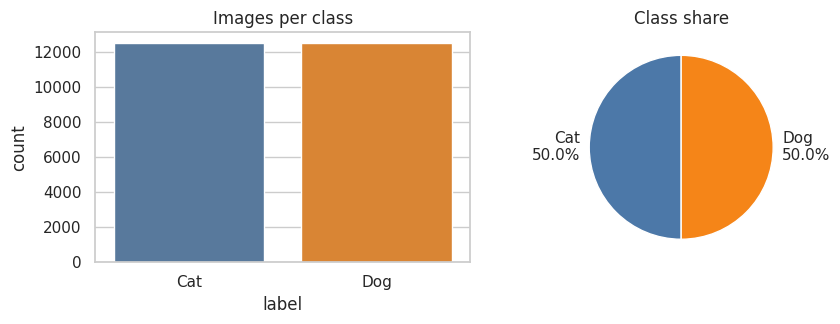

**Q9:** Cat = **50.00%**, Dog = **50.00%** (difference 0.00 percentage points). The dataset is **well balanced**, so plain accuracy is a meaningful metric, a majority-class baseline will score ≈ 50 %, and no re-weighting / resampling is required.

In [ ]:
pct = (counts / counts.sum() * 100).round(2)
display(pd.DataFrame({"images": counts, "percent": pct}))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette=["#4C78A8", "#F58518"], ax=ax[0], legend=False)
ax[0].set_title("Images per class"); ax[0].set_ylabel("count")
ax[1].pie(counts.values, labels=[f"{k}\n{v:.1f}%" for k, v in pct.items()], colors=["#4C78A8", "#F58518"], startangle=90)
ax[1].set_title("Class share")
plt.tight_layout(); plt.show()
diff = abs(pct.get("Cat", 0) - pct.get("Dog", 0))
md(f"**Q9:** Cat = **{pct.get('Cat',0):.2f}%**, Dog = **{pct.get('Dog',0):.2f}%** (difference {diff:.2f} percentage points). "
   + ("The dataset is **well balanced**, so plain accuracy is a meaningful metric, a majority-class baseline will score ≈ 50 %, "
      "and no re-weighting / resampling is required." if diff < 5 else
      "The dataset is **imbalanced** – prefer F1 / ROC-AUC over accuracy and consider class weights."))

### Q11. Unique image file formats

In [ ]:
fmt = pd.DataFrame({
    "by file extension": meta["extension"].value_counts(),
}).fillna(0).astype(int)
display(fmt)
print("Actual decoded format (PIL):", meta["format"].value_counts(dropna=False).to_dict())
print(f"Files whose extension does not match the real format: {int(meta['ext_mismatch'].sum())}")
print("Non-image extensions present:", sorted(set(meta.loc[~meta['is_image_ext'], 'extension'])) or "none")
md(f"**Q11:** the unique file extensions are **{', '.join(sorted(meta['extension'].unique()))}**; "
   f"the decoded formats are **{', '.join(sorted(map(str, meta['format'].dropna().unique())))}**.")

,by file extension
extension,
.jpg,24998


Actual decoded format (PIL): {'JPEG': 24769, 'BMP': 173, 'GIF': 51, 'PNG': 4, 'PSD': 1}
Files whose extension does not match the real format: 229
Non-image extensions present: none


**Q11:** the unique file extensions are **.jpg**; the decoded formats are **BMP, GIF, JPEG, PNG, PSD**.

### Q12. Minimum, maximum, mean and median dimensions

In [ ]:
ok = meta[meta["valid"]].copy()
ok["pixels"] = ok["width"] * ok["height"]
ok["aspect"] = ok["width"] / ok["height"]
stats = ok[["width", "height", "pixels", "file_size"]].agg(["min", "max", "mean", "median"]).T.round(1)
display(stats)

,min,max,mean,median
width,4.0,500.0,404.4,448.0
height,4.0,500.0,361.0,375.0
pixels,16.0,250000.0,151512.7,175500.0
file_size,351.0,980328.0,33957.4,27201.5


### Q13. Distribution of widths and heights

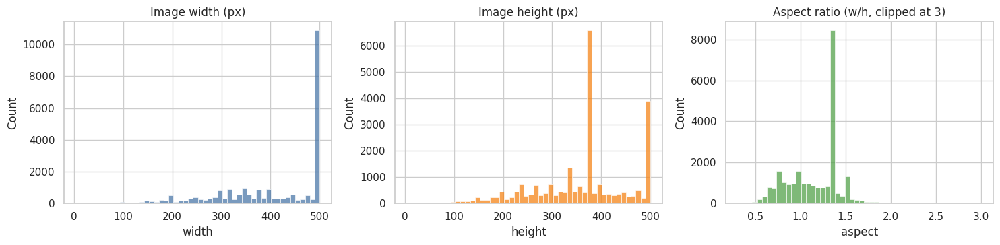

**Q13 – observations**
- Median size is **448 × 375** px, but widths range from 4 to 500 and heights from 4 to 500 → **the images are not uniform**, so they must be resized.
- The most common sizes are 500×375 (5,867), 375×500 (488), 500×333 (427).
- The distributions are right-skewed: most images are a few hundred pixels wide with a long tail of very large photos.
- **11.7%** of images have a shorter side below 224 px (up-scaling them to 224 adds no real detail).
- Aspect ratios cluster around 4:3 / 3:4 / 1:1 – a plain resize to a square distorts some images slightly.

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
sns.histplot(ok["width"], bins=50, ax=ax[0], color="#4C78A8"); ax[0].set_title("Image width (px)")
sns.histplot(ok["height"], bins=50, ax=ax[1], color="#F58518"); ax[1].set_title("Image height (px)")
sns.histplot(ok["aspect"].clip(0, 3), bins=50, ax=ax[2], color="#54A24B"); ax[2].set_title("Aspect ratio (w/h, clipped at 3)")
plt.tight_layout(); plt.show()

mode_wh = ok.groupby(["width", "height"]).size().sort_values(ascending=False).head(3)
small = (ok[["width", "height"]].min(axis=1) < 224).mean() * 100
md(f"**Q13 – observations**\n"
   f"- Median size is **{ok['width'].median():.0f} × {ok['height'].median():.0f}** px, but widths range from {ok['width'].min():.0f} to {ok['width'].max():.0f} and heights from {ok['height'].min():.0f} to {ok['height'].max():.0f} → **the images are not uniform**, so they must be resized.\n"
   f"- The most common sizes are {', '.join(f'{w}×{h} ({c:,})' for (w,h),c in mode_wh.items())}.\n"
   f"- The distributions are right-skewed: most images are a few hundred pixels wide with a long tail of very large photos.\n"
   f"- **{small:.1f}%** of images have a shorter side below 224 px (up-scaling them to 224 adds no real detail).\n"
   f"- Aspect ratios cluster around 4:3 / 3:4 / 1:1 – a plain resize to a square distorts some images slightly.")

### Q14. Twenty random images with labels

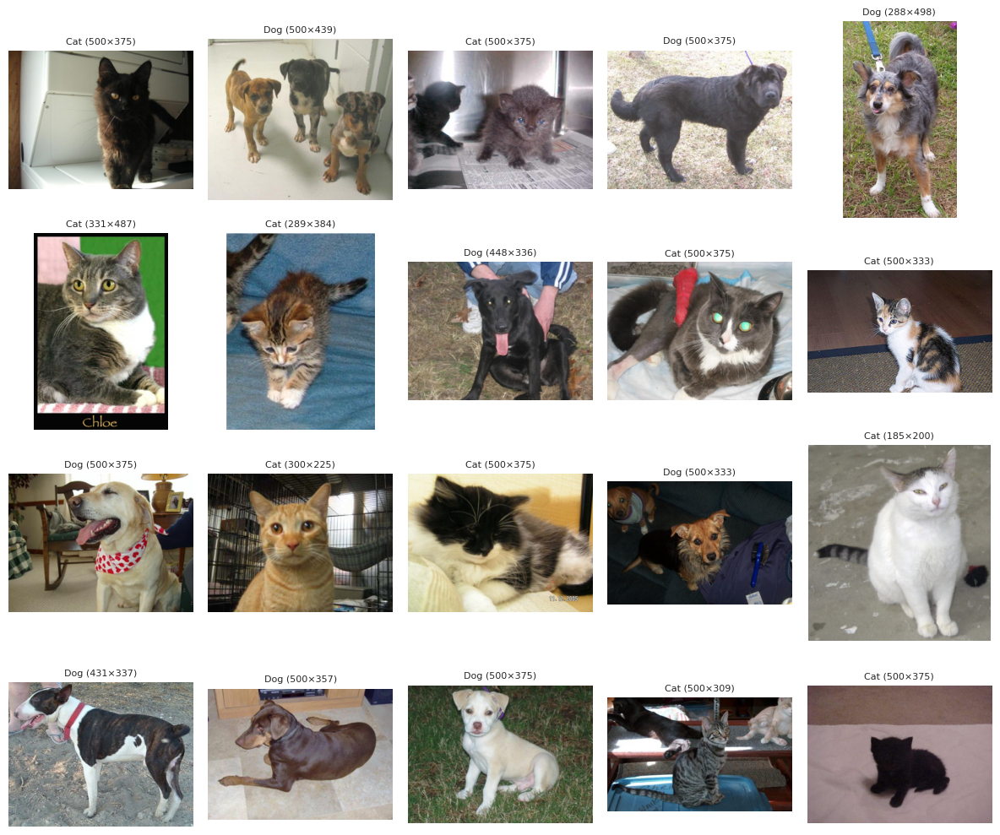

In [ ]:
rng = np.random.default_rng(SEED)
sample20 = ok.sample(20, random_state=SEED)
show_images(sample20["path"].tolist(), [f"{l} ({w}×{h})" for l, w, h in zip(sample20["label"], sample20["width"].astype(int), sample20["height"].astype(int))], ncols=5)

### Q15. Cats vs Dogs side by side

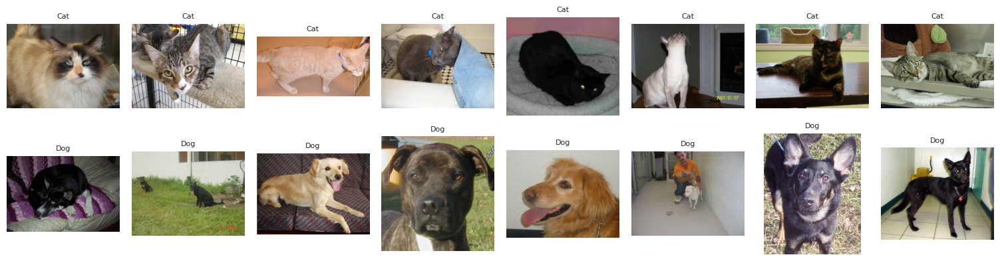

In [ ]:
k = 8
cats = ok[ok["label"] == "Cat"].sample(k, random_state=SEED + 1)["path"].tolist()
dogs = ok[ok["label"] == "Dog"].sample(k, random_state=SEED + 2)["path"].tolist()
show_images(cats + dogs, ["Cat"] * k + ["Dog"] * k, ncols=k, size=1.9)

**Q15 – visual differences (what a model can latch onto):**
* **Face / snout shape** – cats have short, flat muzzles and a more triangular face; dogs show a huge range from short-snouted to long-nosed breeds.
* **Ears** – cats: upright triangular ears; dogs: upright, floppy, or folded depending on breed.
* **Body and posture** – cats are more often curled, perched or in close-up portraits; dogs more often appear outdoors, standing or running with a leash or ball.
* **Background / context** – sofas and windows vs. grass and streets (a *spurious* cue a CNN may exploit).
* **Why it is hard:** huge intra-class variation (breeds, colours, poses), partial views, multiple animals and people in the frame – the overlap is exactly what makes raw-pixel models struggle and CNNs shine.

---
# Phase 3 — Data Quality & Image Cleaning

### Q16. Corrupted, unreadable or invalid files

In [ ]:
bad = dc.detect_and_record_corrupted(meta, report_csv=REPORTS_DIR / "corrupted_files.csv")
bad_in_class = bad[bad["label"] != "Unknown"]
print(f"Problematic files (unreadable / empty / not an image): {len(bad)}  "
      f"(Cat: {(bad['label']=='Cat').sum()}, Dog: {(bad['label']=='Dog').sum()}, outside class folders: {(bad['label']=='Unknown').sum()})")
if len(bad):
    display(bad[["path", "label", "file_size", "extension", "error"]].head(15))
    print(bad["error"].str.split(":").str[0].value_counts())
print(f"\nAdditionally: {int(meta['ext_mismatch'].sum())} files have an extension that does not match their real format "
      f"(still readable → kept, but re-encoded in the cleaned set).")
md(f"**Q16:** **{len(bad)}** problematic files were found (details saved to `reports/corrupted_files.csv`).")

Problematic files (unreadable / empty / not an image): 0  (Cat: 0, Dog: 0, outside class folders: 0)

Additionally: 229 files have an extension that does not match their real format (still readable → kept, but re-encoded in the cleaned set).


**Q16:** **0** problematic files were found (details saved to `reports/corrupted_files.csv`).

### Q17. Function that detects and removes / records corrupted images
`dc.scan_image()` fully decodes each file (`verify()` **and** `load()`, so truncated files are caught too) and `dc.detect_and_record_corrupted()` writes a CSV report and — if `quarantine_dir` is given — **moves** the bad files out of the dataset (safer than deleting). The raw folder is left untouched here; the cleaned dataset simply never includes them.

In [ ]:
print(inspect.getsource(dc.detect_and_record_corrupted))

def detect_and_record_corrupted(df, report_csv=None, quarantine_dir=None):
    """Record every unreadable file (CSV report) and optionally MOVE it to a quarantine folder."""
    import shutil
    bad = df[~df["valid"]].copy()
    if report_csv is not None:
        bad.to_csv(report_csv, index=False)
    if quarantine_dir is not None:
        for p, lab in zip(bad["path"], bad["label"]):
            dst = Path(quarantine_dir) / str(lab)
            dst.mkdir(parents=True, exist_ok=True)
            shutil.move(p, dst / Path(p).name)
    return bad



### Q18. Duplicate images
We compute an **MD5** (byte-identical copies) and a 256-bit **difference hash** (same picture re-saved / lightly resized) for every valid image.

hashing:   0%|          | 0/24998 [00:00<?, ?it/s]

Exact (MD5) duplicate groups : 28  → 30 redundant copies
Near-duplicate (dHash) groups: 30  → 32 redundant copies
Groups that appear under BOTH classes (label conflicts): MD5 2, dHash 2


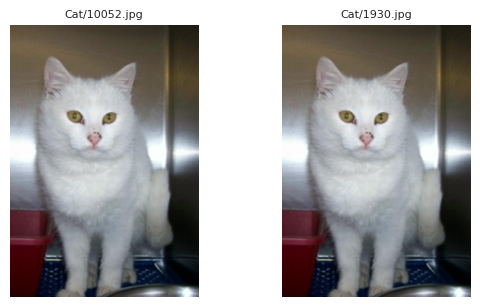

In [ ]:
valid = ok.drop(columns=["pixels", "aspect"]).copy()
valid = dc.add_hashes(valid)

dup_md5_rows = valid[valid["md5"].notna() & valid.duplicated("md5", keep=False)]
dup_dh_rows  = valid[valid["dhash"].notna() & valid.duplicated("dhash", keep=False)]
cross_md5 = valid[valid["md5"].notna()].groupby("md5")["label"].nunique()
cross_dh  = valid[valid["dhash"].notna()].groupby("dhash")["label"].nunique()
print(f"Exact (MD5) duplicate groups : {dup_md5_rows['md5'].nunique():,}  → {valid.duplicated('md5').sum():,} redundant copies")
print(f"Near-duplicate (dHash) groups: {dup_dh_rows['dhash'].nunique():,}  → {valid.duplicated('dhash').sum():,} redundant copies")
print(f"Groups that appear under BOTH classes (label conflicts): MD5 {(cross_md5>1).sum()}, dHash {(cross_dh>1).sum()}")

grp = dup_dh_rows.groupby("dhash").head(2)
if len(grp):
    first = grp["dhash"].iloc[0]
    pair = grp[grp["dhash"] == first]["path"].tolist()[:2]
    show_images(pair, [Path(p).parent.name + "/" + Path(p).name for p in pair], ncols=2, size=3)

**Q18 – how duplicates hurt training and evaluation**
1. **Data leakage** – if one copy lands in *train* and another in *test*, the model is "tested" on an image it memorised, so reported accuracy is inflated and does not reflect real-world performance.
2. **Biased learning / over-weighting** – duplicated pictures count several times in the loss, pulling the model towards them.
3. **Misleading validation** – early stopping and hyper-parameter selection tune to leaked images.
4. **Label noise** – if the same image is stored under both *Cat* and *Dog*, the model receives contradictory supervision.
5. **Wasted compute** – extra epochs on redundant data.

Therefore exact duplicates are removed (keeping one copy), near-duplicates are removed per class, and any image that appears under both classes is dropped completely.

### Q19. Unusual dimensions or file sizes (anomalies)

,images,percent
tiny image (shorter side < 32px),1,0.00
extreme aspect ratio (>3 or <1/3),5,0.02
very small file (< 2 KB),50,0.20
very large resolution (IQR×3 rule),0,0.00
very large file (IQR×3 rule),853,3.41


Images with at least one flag: 907


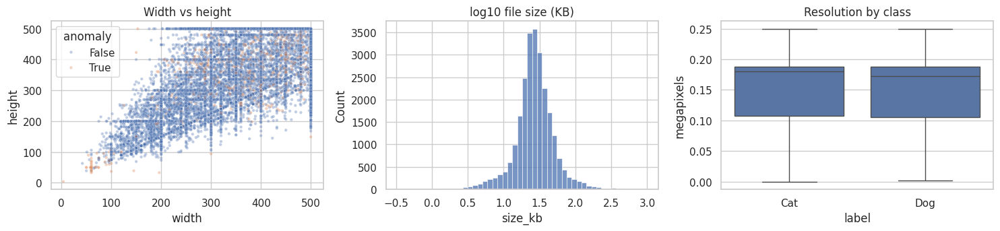

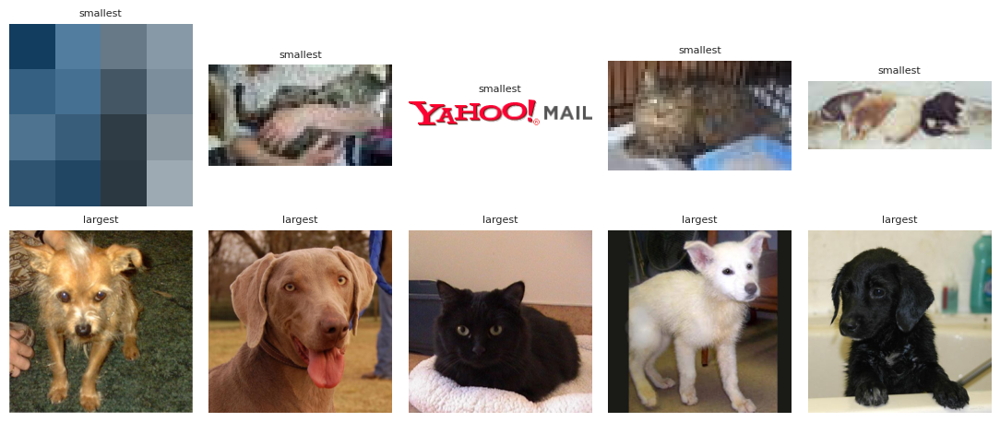

In [ ]:
a = valid.copy()
a["min_side"] = a[["width", "height"]].min(axis=1)
a["max_side"] = a[["width", "height"]].max(axis=1)
a["aspect"] = a["width"] / a["height"]
a["pixels"] = a["width"] * a["height"]
a["size_kb"] = a["file_size"] / 1024

def iqr_upper(s, k=3.0):
    q1, q3 = s.quantile([0.25, 0.75]); return q3 + k * (q3 - q1)

flags = {
    f"tiny image (shorter side < {MIN_SIDE}px)": a["min_side"] < MIN_SIDE,
    "extreme aspect ratio (>3 or <1/3)": (a["aspect"] > 3) | (a["aspect"] < 1 / 3),
    "very small file (< 2 KB)": a["file_size"] < 2000,
    "very large resolution (IQR×3 rule)": a["pixels"] > iqr_upper(a["pixels"]),
    "very large file (IQR×3 rule)": a["size_kb"] > iqr_upper(a["size_kb"]),
}
summary = pd.DataFrame({"images": {k: int(v.sum()) for k, v in flags.items()}})
summary["percent"] = (summary["images"] / len(a) * 100).round(2)
display(summary)
a["anomaly"] = pd.concat(flags, axis=1).any(axis=1)
print("Images with at least one flag:", int(a["anomaly"].sum()))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
sns.scatterplot(data=a, x="width", y="height", hue="anomaly", alpha=.35, s=10, ax=ax[0]); ax[0].set_title("Width vs height")
sns.histplot(np.log10(a["size_kb"].clip(lower=0.1)), bins=50, ax=ax[1]); ax[1].set_title("log10 file size (KB)")
sns.boxplot(x=a["label"], y=a["pixels"] / 1e6, ax=ax[2]); ax[2].set_ylabel("megapixels"); ax[2].set_title("Resolution by class")
plt.tight_layout(); plt.show()

ex = a.sort_values("min_side").head(5)["path"].tolist() + a.sort_values("pixels", ascending=False).head(5)["path"].tolist()
show_images(ex, ["smallest"] * 5 + ["largest"] * 5, ncols=5, size=2.2)

**Q19 – decision:** tiny images carry almost no visual information (a 20-px image up-sampled to 128 px is a blur), so images whose shorter side is below `MIN_SIDE` are **removed**. Very large images, unusual aspect ratios and large files are genuine photos – they are **kept** and handled by resizing; very small *files* are inspected above but kept unless they are also tiny in pixels.

### Q20. Grayscale, RGB and RGBA images

,images,channels
mode,,
RGB,24931,3
P,57,1
L,5,1
CMYK,3,4
RGBA,2,4


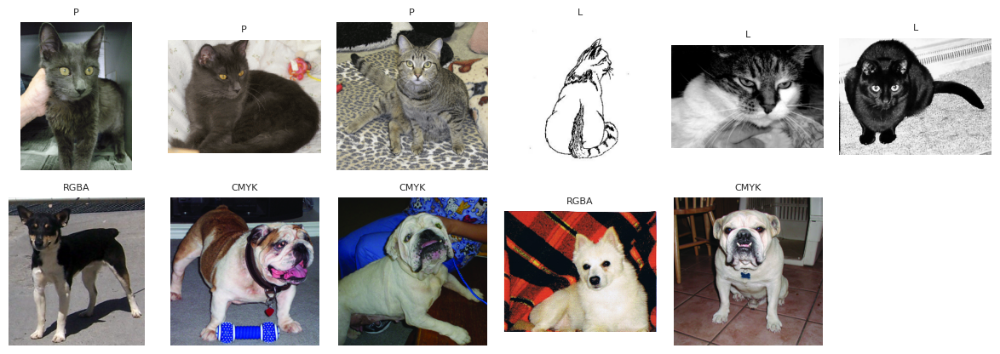

In [ ]:
mode_counts = a["mode"].value_counts()
display(pd.DataFrame({"images": mode_counts, "channels": [len(Image.new(m, (1, 1)).getbands()) for m in mode_counts.index]}))
odd = a[a["mode"] != "RGB"].groupby("mode").head(3)
if len(odd):
    show_images(odd["path"].tolist(), odd["mode"].tolist(), ncols=6, size=2.0)

**Q20 – why standardise channels:** a network's first layer has a **fixed number of input channels** (3 for RGB). A grayscale image (1 channel) or RGBA image (4 channels) would either crash the pipeline or silently produce tensors of different shapes, and palette (`P`) / `CMYK` images would be interpreted with the wrong colour meaning. Every image is therefore converted to **3-channel RGB** (`dc.to_rgb`): grayscale is replicated across channels, CMYK/palette are colour-converted, and transparent pixels are composited on a white background (instead of becoming black).

### Q21. Create the cleaned dataset

In [ ]:
n0 = len(in_class)
steps = [("Files inside class folders (initial scan)", n0)]

df = valid[valid["label"] != "Unknown"].copy()
steps.append(("after removing unreadable / corrupted / non-image files", len(df)))

# label conflicts: same image under both classes → drop every copy
conf_md5 = cross_md5[cross_md5 > 1].index
conf_dh = cross_dh[cross_dh > 1].index
df = df[~(df["md5"].isin(conf_md5) | df["dhash"].isin(conf_dh))]
steps.append(("after removing label-conflict images (in both classes)", len(df)))

df = df[~(df["md5"].notna() & df.duplicated("md5", keep="first"))]
steps.append(("after removing exact (MD5) duplicates", len(df)))

if REMOVE_NEAR_DUPLICATES:
    df = df[~(df["dhash"].notna() & df.duplicated("dhash", keep="first"))]
    steps.append(("after removing near-duplicates (dHash)", len(df)))

df = df[df[["width", "height"]].min(axis=1) >= MIN_SIDE]
steps.append((f"after removing tiny images (< {MIN_SIDE}px)", len(df)))

clean_df = dc.build_cleaned_dataset(df, CLEAN_DIR, max_side=CLEAN_MAX_SIDE)
failed = int((~clean_df["clean_ok"]).sum())
clean_df = clean_df[clean_df["clean_ok"]].reset_index(drop=True)
steps.append(("after re-encoding to RGB JPEG (failures dropped)", len(clean_df)))

waterfall = pd.DataFrame(steps, columns=["step", "images"])
waterfall["removed"] = (-waterfall["images"].diff()).fillna(0).astype(int)
display(waterfall)
clean_df.to_csv(REPORTS_DIR / "clean_manifest.csv", index=False)
clean_df.to_csv(PROC_DIR / "clean_manifest.csv", index=False)

cc = clean_df["label"].value_counts()
md(f"**Q21 – cleaned dataset:** **{len(clean_df):,}** images remain "
   f"(Cat {cc.get('Cat',0):,} = {cc.get('Cat',0)/len(clean_df)*100:.1f}%, Dog {cc.get('Dog',0):,} = {cc.get('Dog',0)/len(clean_df)*100:.1f}%), "
   f"i.e. {n0 - len(clean_df):,} images removed ({(n0-len(clean_df))/max(n0,1)*100:.2f}%). "
   f"All are now **3-channel RGB JPEGs with the longest side ≤ {CLEAN_MAX_SIDE}px** in `{CLEAN_DIR}`; manifest saved to `reports/clean_manifest.csv`.")

cleaning:   0%|          | 0/24963 [00:00<?, ?it/s]

,step,images,removed
0,Files inside class folders (initial scan),24998,0
1,after removing unreadable / corrupted / non-im...,24998,0
2,after removing label-conflict images (in both ...,24992,6
3,after removing exact (MD5) duplicates,24966,26
4,after removing near-duplicates (dHash),24964,2
5,after removing tiny images (< 32px),24963,1
6,after re-encoding to RGB JPEG (failures dropped),24963,0


**Q21 – cleaned dataset:** **24,963** images remain (Cat 12,478 = 50.0%, Dog 12,485 = 50.0%), i.e. 35 images removed (0.14%). All are now **3-channel RGB JPEGs with the longest side ≤ 256px** in `/content/data/cleaned`; manifest saved to `reports/clean_manifest.csv`.

---
# Phase 4 — Image Preprocessing

### Q22. Why can't ML algorithms process images of different dimensions directly?
Classical ML models (Logistic Regression, SVM, KNN, Random Forest) and neural-network input layers expect a **fixed-length feature vector / fixed-shape tensor**. A 500×375×3 image has 562,500 numbers while a 300×200×3 image has 180,000 – they cannot be stacked into one matrix, the weight matrix of the first layer would not fit both, and distances between samples (KNN/SVM) would be undefined. Every image must therefore be brought to a **common height × width** (and channel count) before training.

### Q23. Common size and why
| Used for | Size | Reason |
|---|---|---|
| Traditional ML (pixels, HOG, PCA) | **64 × 64** | 64×64×3 = 12,288 features – large enough to keep the silhouette, small enough that SVM / KNN / Random Forest train in minutes |
| Custom CNNs | **128 × 128** | The brief's baseline; fine textures (fur, ears) are visible, a 3-block CNN trains quickly on a T4 |
| Transfer learning (MobileNetV2) | **224 × 224** | Native ImageNet resolution of the pretrained backbone → best use of the learned filters |

Images are resized *directly* to a square (slight aspect distortion, the same at train and inference time). The cleaned files are already ≤256 px, so little information is lost.

In [ ]:
%%writefile src/preprocessing.py
"""Preprocessing helpers shared by the notebook, training scripts and the app."""
from concurrent.futures import ThreadPoolExecutor
import os

import numpy as np
from PIL import Image

CLASS_NAMES = ["Cat", "Dog"]
LABEL_MAP = {"Cat": 0, "Dog": 1}          # Dog is the positive class
N_WORKERS = min(32, (os.cpu_count() or 2) * 4)


def load_image_array(path, size, gray=False):
    """Load -> RGB (or L) -> resize to size x size -> uint8 array."""
    with Image.open(path) as im:
        im = im.convert("L" if gray else "RGB").resize((size, size), Image.BILINEAR)
        return np.asarray(im, dtype=np.uint8)


def load_image_batch(paths, size, gray=False, workers=N_WORKERS):
    with ThreadPoolExecutor(workers) as ex:
        arrs = list(ex.map(lambda p: load_image_array(p, size, gray), paths))
    return np.stack(arrs)


def normalize(x_uint8):
    """0-255 -> 0-1 (float32)."""
    return x_uint8.astype("float32") / 255.0


def flatten(x):
    return x.reshape(len(x), -1)


def make_dataset(paths, labels, img_size, batch_size=64, shuffle=False, seed=42, augment=None):
    """tf.data pipeline: file -> decode -> resize -> float32 [0,255] -> batch (-> augment, train only)."""
    import tensorflow as tf
    autotune = tf.data.AUTOTUNE

    def _load(path, label):
        img = tf.io.read_file(path)
        img = tf.image.decode_jpeg(img, channels=3)
        img = tf.image.resize(img, (img_size, img_size), antialias=True)
        return tf.cast(img, tf.float32), tf.cast(label, tf.float32)

    ds = tf.data.Dataset.from_tensor_slices((np.asarray(paths, dtype=str), np.asarray(labels, dtype="float32")))
    if shuffle:
        ds = ds.shuffle(len(paths), seed=seed, reshuffle_each_iteration=True)
    ds = ds.map(_load, num_parallel_calls=autotune).batch(batch_size)
    if augment is not None:
        ds = ds.map(lambda x, y: (augment(x), y), num_parallel_calls=autotune)
    return ds.prefetch(autotune)

Writing src/preprocessing.py


In [ ]:
import src.preprocessing as pp
importlib.reload(pp)

# ── Q24: images → NumPy arrays ──
sample = clean_df.sample(min(200, len(clean_df)), random_state=SEED)
X_sample = pp.load_image_batch(sample["clean_path"].tolist(), CNN_IMG)
print("Array shape :", X_sample.shape, "→ (n_images, height, width, channels)")
print("dtype       :", X_sample.dtype, "| min/max:", X_sample.min(), X_sample.max())
print("One image   :", X_sample[0].shape, "=", X_sample[0].size, "values")
md(f"**Q24:** each image becomes a `uint8` tensor of shape `({CNN_IMG}, {CNN_IMG}, 3)`; a batch of {len(X_sample)} has shape `{X_sample.shape}`.")

Array shape : (200, 128, 128, 3) → (n_images, height, width, channels)
dtype       : uint8 | min/max: 0 255
One image   : (128, 128, 3) = 49152 values


**Q24:** each image becomes a `uint8` tensor of shape `(128, 128, 3)`; a batch of 200 has shape `(200, 128, 128, 3)`.

### Q25. Normalise pixels from 0–255 to 0–1

Before: dtype=uint8, min=0, max=255, mean=113.0
After : dtype=float32, min=0.00, max=1.00, mean=0.443


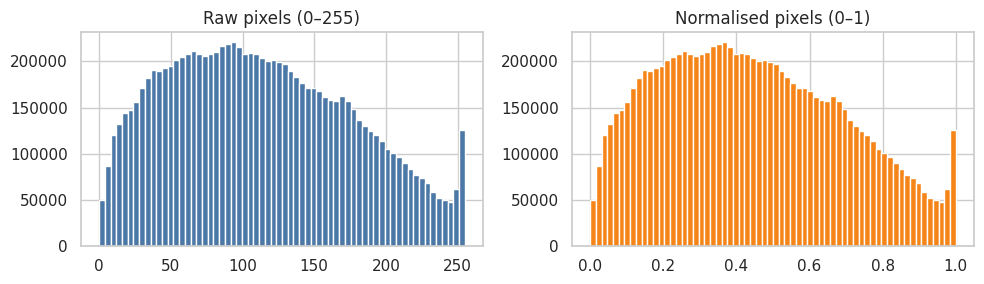

In [ ]:
X_norm = pp.normalize(X_sample)
print(f"Before: dtype={X_sample.dtype}, min={X_sample.min()}, max={X_sample.max()}, mean={X_sample.mean():.1f}")
print(f"After : dtype={X_norm.dtype}, min={X_norm.min():.2f}, max={X_norm.max():.2f}, mean={X_norm.mean():.3f}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(X_sample.ravel(), bins=64, color="#4C78A8"); ax[0].set_title("Raw pixels (0–255)")
ax[1].hist(X_norm.ravel(), bins=64, color="#F58518"); ax[1].set_title("Normalised pixels (0–1)")
plt.tight_layout(); plt.show()

**Q25 – why normalise?**
* **Stable, faster optimisation** – gradients and weight updates stay in a sensible range; raw 0–255 inputs make gradient descent oscillate or saturate sigmoid/ReLU units.
* **Scale-sensitive algorithms** – KNN, SVM (RBF) and Logistic Regression depend on distances / dot products, so all features must be on the same scale.
* **Better initialisation behaviour** – default weight initialisers assume inputs of roughly unit scale.
* **Consistency** – exactly the same scaling must be applied at inference. In the deep-learning models the scaling is built **inside the model** (`Rescaling` layer), so the deployed app cannot forget it.

### Q26. Target encoding

In [ ]:
clean_df["y"] = clean_df["label"].map(pp.LABEL_MAP).astype(int)
print("Encoding:", pp.LABEL_MAP, "(Dog = positive class)")
print(clean_df.groupby("label")["y"].agg(["first", "count"]))

Encoding: {'Cat': 0, 'Dog': 1} (Dog = positive class)
       first  count
label              
Cat        0  12478
Dog        1  12485


### Q27. Train / validation / test split
**70 % train / 15 % validation / 15 % test**, stratified by class and shuffled with a fixed seed.
* Train (70 %) gives the models enough data to learn from the many breeds / poses.
* Validation (15 %) is used for early stopping, hyper-parameter choices and model selection.
* Test (15 %) is a large-enough sample (thousands of images with the full dataset) to give a tight estimate of the final accuracy (±≈0.5 %), and is **only used once, at the very end**.
The split is done on the **cleaned, de-duplicated** file list, and the file lists are saved for reproducibility.

In [ ]:
from sklearn.model_selection import train_test_split
idx = np.arange(len(clean_df))
tr_idx, tmp_idx = train_test_split(idx, test_size=SPLIT["val"] + SPLIT["test"], stratify=clean_df["y"], random_state=SEED)
va_idx, te_idx = train_test_split(tmp_idx, test_size=SPLIT["test"] / (SPLIT["val"] + SPLIT["test"]),
                                  stratify=clean_df["y"].iloc[tmp_idx], random_state=SEED)
clean_df["split"] = "train"
clean_df.loc[va_idx, "split"] = "val"
clean_df.loc[te_idx, "split"] = "test"

train_df = clean_df[clean_df["split"] == "train"].reset_index(drop=True)
val_df   = clean_df[clean_df["split"] == "val"].reset_index(drop=True)
test_df  = clean_df[clean_df["split"] == "test"].reset_index(drop=True)

split_cols = ["clean_path", "path", "label", "y", "split", "md5", "dhash"]
clean_df[split_cols].to_csv(REPORTS_DIR / "splits.csv", index=False)
clean_df[split_cols].to_csv(PROC_DIR / "splits.csv", index=False)
for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    d[["clean_path", "y"]].to_csv(PROC_DIR / f"{n}_files.csv", index=False)
print(f"train={len(train_df):,}  val={len(val_df):,}  test={len(test_df):,}  (split lists saved in reports/ and data/processed/)")

train=17,474  val=3,744  test=3,745  (split lists saved in reports/ and data/processed/)


### Q28. Why stratified sampling?

In [ ]:
tab = pd.crosstab(clean_df["split"], clean_df["label"], normalize="index").mul(100).round(2)
tab["n"] = clean_df["split"].value_counts()
display(tab.loc[["train", "val", "test"]])

label,Cat,Dog,n
split,,,
train,49.99,50.01,17474
val,49.97,50.03,3744
test,49.99,50.01,3745


**Q28:** stratification forces every split to have (almost exactly) the **same Cat/Dog ratio as the full dataset** (see table). A purely random split can – especially in small validation/test sets – produce a different class mix, which makes metrics noisy, makes validation and test scores incomparable, and can bias early stopping. Even though this dataset is nearly balanced, stratification is cheap insurance and it becomes essential if the class ratio is skewed.

### Q29. How data leakage can occur — and how to prevent it

In [ ]:
# (a) Duplicate leakage: naive random split of the UN-cleaned file list (duplicates still present)
naive_tr, naive_te = train_test_split(valid, test_size=0.15, random_state=SEED)
leak_md5 = int(naive_te["md5"].isin(set(naive_tr["md5"])).sum())
leak_dh  = int(naive_te["dhash"].isin(set(naive_tr["dhash"].dropna())).sum())
print(f"(a) NAIVE split (no de-duplication): {leak_md5} test images are byte-identical to a training image, "
      f"{leak_dh} are near-identical → the test score would be inflated.")

# prevention check on the REAL split: no hash may appear in two splits
for a_, b_ in [("train", "val"), ("train", "test"), ("val", "test")]:
    A, B = clean_df[clean_df["split"] == a_], clean_df[clean_df["split"] == b_]
    ov = len(set(A["md5"]) & set(B["md5"])) + len(set(A["dhash"].dropna()) & set(B["dhash"].dropna()))
    print(f"    overlap {a_:5s} ↔ {b_:5s}: {ov}")
    assert ov == 0, "leakage detected!"
print("    ✔ cleaned split is leakage-free")

# (b) Pre-processing leakage: fitting a scaler on train+test instead of train only
Xa = pp.flatten(pp.normalize(pp.load_image_batch(train_df.sample(min(300, len(train_df)), random_state=SEED)["clean_path"], 32)))
Xb = pp.flatten(pp.normalize(pp.load_image_batch(test_df.sample(min(300, len(test_df)), random_state=SEED)["clean_path"], 32)))
from sklearn.preprocessing import StandardScaler
leaky = StandardScaler().fit(np.vstack([Xa, Xb]))
proper = StandardScaler().fit(Xa)
print(f"(b) mean |difference| between leaky scaler (fit on train+test) and proper scaler (train only): "
      f"{np.abs(leaky.mean_ - proper.mean_).mean():.5f} → test-set statistics would silently influence training.")

(a) NAIVE split (no de-duplication): 9 test images are byte-identical to a training image, 10 are near-identical → the test score would be inflated.
    overlap train ↔ val  : 0
    overlap train ↔ test : 0
    overlap val   ↔ test : 0
    ✔ cleaned split is leakage-free
(b) mean |difference| between leaky scaler (fit on train+test) and proper scaler (train only): 0.00534 → test-set statistics would silently influence training.


**Q29 – leakage sources and prevention**
| Leakage source | Demonstrated above | Prevention used here |
|---|---|---|
| **Duplicate / near-duplicate images in different splits** | (a) | MD5 + dHash de-duplication **before** splitting; automatic assertion that no hash crosses splits |
| **Fitting scalers / PCA / feature selectors on all data** | (b) | Every transform is `fit` on the **training** subset only and merely `transform`s val/test |
| **Augmenting before splitting** (augmented copies of one photo end up in train *and* test) | – | Split first; augmentation is applied **on the fly to training batches only** |
| **Tuning on the test set** | – | All model selection uses the validation set; test is evaluated once at the end |
| **Same animal in many photos** (burst shots) | – | Near-duplicate removal reduces it; a group-aware split would need extra metadata (listed as future work) |

---
# Phase 5 — Traditional Machine Learning (raw pixels)

Classical models are trained on **64×64 RGB pixels** from a **stratified subset of the training split** (to keep SVM/KNN/RF tractable) and are scored on the **same validation set**. Test-set scores are produced once, at the end, for *all* models.

In [ ]:
%%writefile src/train_ml.py
"""Training / evaluation helpers for the classical ML experiments."""
import time

import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score, roc_auc_score)


def get_scores(model, X):
    """Probability of the positive class (Dog); falls back to the SVM decision function."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


def compute_metrics(y_true, y_pred, y_score):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0),
            "roc_auc": roc_auc_score(y_true, y_score)}


def fit_timed(model, X, y):
    t0 = time.perf_counter()
    model.fit(X, y)
    return model, time.perf_counter() - t0


def evaluate_model(model, X, y):
    pred = model.predict(X)
    score = get_scores(model, X)
    return compute_metrics(y, pred, score), pred, score


def tune_on_val(factory, values, Xtr, ytr, Xva, yva):
    """Fit one model per hyper-parameter value, keep the best on VALIDATION accuracy."""
    rows, best = [], None
    for v in values:
        model, t = fit_timed(factory(v), Xtr, ytr)
        m, _, _ = evaluate_model(model, Xva, yva)
        rows.append({"param": v, "val_accuracy": m["accuracy"], "val_f1": m["f1"], "train_time_s": t})
        if best is None or m["accuracy"] > best[0]:
            best = (m["accuracy"], v, model, t)
    return best[2], best[1], best[3], pd.DataFrame(rows)


def save_ml_model(model, path):
    joblib.dump(model, path, compress=3)
    import os
    return os.path.getsize(path) / 1e6

Writing src/train_ml.py


In [ ]:
import src.train_ml as tm
importlib.reload(tm)
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix

def subsample(df, n_per_class, seed=SEED):
    parts = [g.sample(min(len(g), n_per_class), random_state=seed) for _, g in df.groupby("label")]
    return pd.concat(parts).sample(frac=1, random_state=seed).reset_index(drop=True)

ml_train = subsample(train_df, ML_TRAIN_PER_CLASS)
ml_val   = subsample(val_df, ML_VAL_PER_CLASS)
ml_test  = test_df                       # the FULL test split – same files as the deep-learning models
ytr, yva, yte = ml_train["y"].values, ml_val["y"].values, ml_test["y"].values

t0 = time.time()
cache = PROC_DIR / f"ml_arrays_{ML_IMG}.npz"
Xtr_u8 = pp.load_image_batch(ml_train["clean_path"], ML_IMG)
Xva_u8 = pp.load_image_batch(ml_val["clean_path"], ML_IMG)
Xte_u8 = pp.load_image_batch(ml_test["clean_path"], ML_IMG)
print(f"Loaded {len(Xtr_u8)+len(Xva_u8)+len(Xte_u8):,} images at {ML_IMG}×{ML_IMG} in {time.time()-t0:.0f}s | "
      f"train {Xtr_u8.shape}, val {Xva_u8.shape}, test {Xte_u8.shape}")

Loaded 9,945 images at 64×64 in 11s | train (5000, 64, 64, 3), val (1200, 64, 64, 3), test (3745, 64, 64, 3)


### Q30. Flattened pixel features — dimensionality

In [ ]:
Xtr_raw = pp.flatten(pp.normalize(Xtr_u8))
Xva_raw = pp.flatten(pp.normalize(Xva_u8))
Xte_raw = pp.flatten(pp.normalize(Xte_u8))
md(f"**Q30:** a 64×64 RGB image flattens to 64 × 64 × 3 = **{64*64*3:,}** features "
   f"(measured: `{Xtr_raw.shape[1]:,}`). Training matrix shape: `{Xtr_raw.shape}`.")

FEATS = {"raw": (Xtr_raw, Xva_raw, Xte_raw)}     # feature sets: (train, val, test)
REG, RES_VAL, VAL_PRED = {}, {}, {}              # model registry, validation metrics, validation predictions
BEST = {}                                        # best hyper-parameters found on validation

def register_ml(name, model, feat, train_time):
    Xva = FEATS[feat][1]
    m, pred, score = tm.evaluate_model(model, Xva, yva)
    m["train_time_s"] = train_time
    RES_VAL[name], VAL_PRED[name] = m, (pred, score)
    REG[name] = dict(kind="ml", model=model, feat=feat, train_time=train_time)
    return m

def plot_cm(ax, y, pred, title):
    cm = confusion_matrix(y, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=pp.CLASS_NAMES, yticklabels=pp.CLASS_NAMES)
    ax.set_title(title, fontsize=10); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    return cm

# baseline for reference
dummy, t = tm.fit_timed(DummyClassifier(strategy="most_frequent"), Xtr_raw, ytr)
register_ml("Majority baseline", dummy, "raw", t)

**Q30:** a 64×64 RGB image flattens to 64 × 64 × 3 = **12,288** features (measured: `12,288`). Training matrix shape: `(5000, 12288)`.

{'accuracy': 0.5,
 'precision': 0.0,
 'recall': 0.0,
 'f1': 0.0,
 'roc_auc': np.float64(0.5),
 'train_time_s': 0.001080322999996497}

### Q31. Logistic Regression on raw pixels

In [ ]:
lr_vals = [1e-3] if FAST_DEBUG else [1e-4, 1e-3, 1e-2]
lr, BEST["lr"], t, tune_lr = tm.tune_on_val(
    lambda C: make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=300, random_state=SEED)),
    lr_vals, Xtr_raw, ytr, Xva_raw, yva)
m = register_ml("Logistic Regression", lr, "raw", t)
display(tune_lr.rename(columns={"param": "C"}))
tr_acc = lr.score(Xtr_raw, ytr)
gap_txt = ("A large gap means the linear model memorises noise in 12,288 correlated pixels."
           if tr_acc - m["accuracy"] > 0.10 else "The gap is small, so over-fitting is limited for this model.")
md(f"**Q31:** best C = `{BEST['lr']}` → validation accuracy **{m['accuracy']:.4f}** (F1 {m['f1']:.4f}). "
   f"Training accuracy is {tr_acc:.4f} (train–validation gap {tr_acc - m['accuracy']:+.3f}). {gap_txt}")

,C,val_accuracy,val_f1,train_time_s
0,0.0001,0.592500,0.580258,10.927800
1,0.0010,0.575833,0.557776,24.405951
2,0.0100,0.561667,0.539405,47.378930


**Q31:** best C = `0.0001` → validation accuracy **0.5925** (F1 0.5803). Training accuracy is 0.6702 (train–validation gap +0.078). The gap is small, so over-fitting is limited for this model.

### Q32. K-Nearest Neighbours (same representation) vs Logistic Regression

In [ ]:
knn_vals = [5] if FAST_DEBUG else [3, 7, 15]
knn, BEST["knn"], t, tune_knn = tm.tune_on_val(
    lambda k: KNeighborsClassifier(n_neighbors=k, n_jobs=-1), knn_vals, Xtr_raw, ytr, Xva_raw, yva)
m = register_ml("KNN", knn, "raw", t)
display(tune_knn.rename(columns={"param": "k"}))
cmp = pd.DataFrame({k: RES_VAL[k] for k in ["Logistic Regression", "KNN"]}).T[["accuracy", "precision", "recall", "f1", "roc_auc", "train_time_s"]].round(4)
display(cmp)
better = cmp["accuracy"].idxmax()
md(f"**Q32:** KNN (k={BEST['knn']}) reaches **{RES_VAL['KNN']['accuracy']:.4f}** vs Logistic Regression **{RES_VAL['Logistic Regression']['accuracy']:.4f}** → "
   f"**{better}** is better on validation. KNN has almost no training cost but slow prediction (distance to every training image in 12,288-D space), and Euclidean distance on raw pixels mostly measures overall colour/brightness similarity rather than 'catness'.")

,k,val_accuracy,val_f1,train_time_s
0,3,0.545000,0.514235,0.037400
1,7,0.561667,0.553480,0.027079
2,15,0.591667,0.595710,0.023852


,accuracy,precision,recall,f1,roc_auc,train_time_s
Logistic Regression,0.5925,0.5982,0.5633,0.5803,0.6239,10.9278
KNN,0.5917,0.5899,0.6017,0.5957,0.6234,0.0239


**Q32:** KNN (k=15) reaches **0.5917** vs Logistic Regression **0.5925** → **Logistic Regression** is better on validation. KNN has almost no training cost but slow prediction (distance to every training image in 12,288-D space), and Euclidean distance on raw pixels mostly measures overall colour/brightness similarity rather than 'catness'.

### Q33. Support Vector Machine (RBF) on pixels

In [ ]:
svm_vals = [1.0] if FAST_DEBUG else [1.0, 10.0]
svm, BEST["svm"], t, tune_svm = tm.tune_on_val(
    lambda C: make_pipeline(StandardScaler(), SVC(kernel="rbf", C=C, gamma="scale")),
    svm_vals, Xtr_raw, ytr, Xva_raw, yva)
m = register_ml("SVM - Raw Pixels", svm, "raw", t)
display(tune_svm.rename(columns={"param": "C"}))
md(f"**Q33:** RBF-SVM (C={BEST['svm']}) → validation accuracy **{m['accuracy']:.4f}**, F1 **{m['f1']:.4f}**, ROC-AUC **{m['roc_auc']:.4f}**, trained in {t:.0f}s.")

,C,val_accuracy,val_f1,train_time_s
0,1.0,0.645000,0.651391,305.281716
1,10.0,0.634167,0.627018,324.603679


**Q33:** RBF-SVM (C=1.0) → validation accuracy **0.6450**, F1 **0.6514**, ROC-AUC **0.7098**, trained in 305s.

### Q34. Random Forest

In [ ]:
rf, t = tm.fit_timed(RandomForestClassifier(n_estimators=200 if not FAST_DEBUG else 50, n_jobs=-1, random_state=SEED), Xtr_raw, ytr)
m = register_ml("Random Forest", rf, "raw", t)
ml_names = ["Logistic Regression", "KNN", "SVM - Raw Pixels", "Random Forest"]
cmp = pd.DataFrame({k: RES_VAL[k] for k in ml_names}).T[["accuracy", "f1", "roc_auc", "train_time_s"]].round(4)
display(cmp)
md(f"**Q34:** Random Forest validation accuracy = **{m['accuracy']:.4f}** vs LR {RES_VAL['Logistic Regression']['accuracy']:.4f} and SVM {RES_VAL['SVM - Raw Pixels']['accuracy']:.4f}. "
   "Trees split on individual pixel values, which carry little meaning on their own (a pixel's role changes with the animal's position), so forests on raw pixels usually land in the same modest range as the other classical models.")

,accuracy,f1,roc_auc,train_time_s
Logistic Regression,0.5925,0.5803,0.6239,10.9278
KNN,0.5917,0.5957,0.6234,0.0239
SVM - Raw Pixels,0.6450,0.6514,0.7098,305.2817
Random Forest,0.6333,0.6014,0.6938,92.4478


**Q34:** Random Forest validation accuracy = **0.6333** vs LR 0.5925 and SVM 0.6450. Trees split on individual pixel values, which carry little meaning on their own (a pixel's role changes with the animal's position), so forests on raw pixels usually land in the same modest range as the other classical models.

### Q35. Comparison table (validation set)

In [ ]:
tab35 = pd.DataFrame({k: RES_VAL[k] for k in ["Majority baseline"] + ml_names}).T[["accuracy", "precision", "recall", "f1", "roc_auc", "train_time_s"]].round(4)
display(tab35.style.highlight_max(subset=["accuracy", "precision", "recall", "f1", "roc_auc"], color="#c6efce").format("{:.4f}"))
tab35.to_csv(REPORTS_DIR / "traditional_ml_val_results.csv")

,accuracy,precision,recall,f1,roc_auc,train_time_s
Majority baseline,0.5000,0.0000,0.0000,0.0000,0.5000,0.0011
Logistic Regression,0.5925,0.5982,0.5633,0.5803,0.6239,10.9278
KNN,0.5917,0.5899,0.6017,0.5957,0.6234,0.0239
SVM - Raw Pixels,0.6450,0.6399,0.6633,0.6514,0.7098,305.2817
Random Forest,0.6333,0.6587,0.5533,0.6014,0.6938,92.4478


### Q36. Confusion matrices — which model makes the fewest errors?

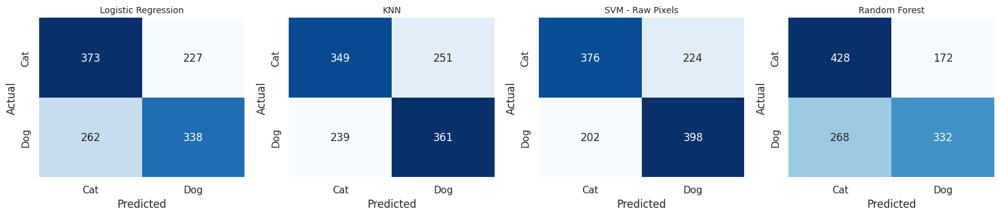

**Q36:** misclassified validation images → Logistic Regression: **489**, KNN: **490**, SVM - Raw Pixels: **426**, Random Forest: **440**. **SVM - Raw Pixels** produces the fewest errors (426 of 1200).

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
errs = {}
for ax, n in zip(axes, ml_names):
    cm = plot_cm(ax, yva, VAL_PRED[n][0], n)
    errs[n] = int(cm.sum() - np.trace(cm))
plt.tight_layout(); plt.show()
best_n = min(errs, key=errs.get)
md(f"**Q36:** misclassified validation images → " + ", ".join(f"{k}: **{v}**" for k, v in errs.items()) +
   f". **{best_n}** produces the fewest errors ({errs[best_n]} of {len(yva)}).")

### Q37. Why do traditional ML algorithms struggle with raw pixels?
1. **Huge dimensionality, few samples** – 12,288 features for a few thousand images invites over-fitting (the curse of dimensionality).
2. **No spatial awareness** – flattening destroys the 2-D neighbourhood structure; a pixel's right neighbour is just another column.
3. **No translation invariance** – the same ear shifted by 5 pixels produces a completely different vector.
4. **Pixels are not semantic features** – colour/brightness depends on lighting, background and breed, not on "cat-ness"; many cats and dogs share similar colours.
5. **Sensitivity to scale, rotation, pose and background clutter** – none of which are modelled.
6. **Distances become uninformative in high-D** (KNN/SVM-RBF), and axis-aligned splits on single pixels (Random Forest) are weak.
CNNs fix this with local filters, weight sharing and pooling, which build position-tolerant edge → texture → part → object features automatically.

---
# Phase 6 — Feature Engineering for Machine Learning

In [ ]:
%%writefile src/feature_engineering.py
"""Alternative image representations: grayscale, HOG."""
import numpy as np


def rgb_to_gray(x_uint8):
    """(N,H,W,3) uint8 -> (N,H,W) float32 in [0,1] using ITU-R 601 luma weights."""
    w = np.array([0.299, 0.587, 0.114], dtype="float32")
    return (x_uint8.astype("float32") @ w) / 255.0


def hog_features(x_gray, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2)):
    """Histogram of Oriented Gradients for each (H,W) grayscale image in [0,1]."""
    from skimage.feature import hog
    feats = [hog(img, orientations=orientations, pixels_per_cell=pixels_per_cell,
                 cells_per_block=cells_per_block, block_norm="L2-Hys", feature_vector=True)
             for img in x_gray]
    return np.asarray(feats, dtype="float32")

Writing src/feature_engineering.py


In [ ]:
import src.feature_engineering as fe
importlib.reload(fe)
Gtr, Gva, Gte = fe.rgb_to_gray(Xtr_u8), fe.rgb_to_gray(Xva_u8), fe.rgb_to_gray(Xte_u8)
FEATS["gray"] = (pp.flatten(Gtr), pp.flatten(Gva), pp.flatten(Gte))
print("Grayscale feature dimension:", FEATS["gray"][0].shape[1], "(vs", Xtr_raw.shape[1], "for RGB)")

gray_models = {
    "Logistic Regression (gray)": lambda: make_pipeline(StandardScaler(), LogisticRegression(C=BEST["lr"], max_iter=300, random_state=SEED)),
    "KNN (gray)": lambda: KNeighborsClassifier(n_neighbors=BEST["knn"], n_jobs=-1),
    "SVM (gray)": lambda: make_pipeline(StandardScaler(), SVC(kernel="rbf", C=BEST["svm"], gamma="scale")),
    "Random Forest (gray)": lambda: RandomForestClassifier(n_estimators=200 if not FAST_DEBUG else 50, n_jobs=-1, random_state=SEED),
}
for name, make in gray_models.items():
    mdl, t = tm.fit_timed(make(), FEATS["gray"][0], ytr)
    register_ml(name, mdl, "gray", t)

pairs = [("Logistic Regression", "Logistic Regression (gray)"), ("KNN", "KNN (gray)"),
         ("SVM - Raw Pixels", "SVM (gray)"), ("Random Forest", "Random Forest (gray)")]
rows = []
for rgb_n, gr_n in pairs:
    rows.append({"model": rgb_n, "RGB acc": RES_VAL[rgb_n]["accuracy"], "Gray acc": RES_VAL[gr_n]["accuracy"],
                 "RGB F1": RES_VAL[rgb_n]["f1"], "Gray F1": RES_VAL[gr_n]["f1"],
                 "RGB time (s)": RES_VAL[rgb_n]["train_time_s"], "Gray time (s)": RES_VAL[gr_n]["train_time_s"]})
cmp38 = pd.DataFrame(rows).set_index("model").round(4)
display(cmp38)
diff = (cmp38["Gray acc"] - cmp38["RGB acc"]).mean()
md(f"**Q38:** on average grayscale changes validation accuracy by **{diff*100:+.2f} points** while using **3× fewer features** and training faster "
   f"(mean time RGB {cmp38['RGB time (s)'].mean():.1f}s vs gray {cmp38['Gray time (s)'].mean():.1f}s). "
   + ("Colour adds little for cat-vs-dog (fur colours overlap heavily); shape and texture carry most of the signal, so grayscale is a much cheaper representation at similar accuracy."
      if abs(diff) < 0.02 else
      ("Colour carries useful information here (grayscale is clearly worse), e.g. typical fur / background colours." if diff < 0 else
       "Dropping colour actually helped, most likely by removing nuisance variation (lighting, background colour) and reducing over-fitting.")))

Grayscale feature dimension: 4096 (vs 12288 for RGB)


,RGB acc,Gray acc,RGB F1,Gray F1,RGB time (s),Gray time (s)
model,,,,,,
Logistic Regression,0.5925,0.5500,0.5803,0.5462,10.9278,1.4050
KNN,0.5917,0.5808,0.5957,0.5840,0.0239,0.0145
SVM - Raw Pixels,0.6450,0.6350,0.6514,0.6468,305.2817,71.7838
Random Forest,0.6333,0.6192,0.6014,0.5974,92.4478,80.2317


**Q38:** on average grayscale changes validation accuracy by **-1.94 points** while using **3× fewer features** and training faster (mean time RGB 102.2s vs gray 38.4s). Colour adds little for cat-vs-dog (fur colours overlap heavily); shape and texture carry most of the signal, so grayscale is a much cheaper representation at similar accuracy.

### Q39. HOG features + SVM

HOG dimension: 1764 per image (extracted in 16s)


,C,val_accuracy,val_f1,train_time_s
0,1.0,0.728333,0.726968,23.687659
1,10.0,0.733333,0.730185,28.637498


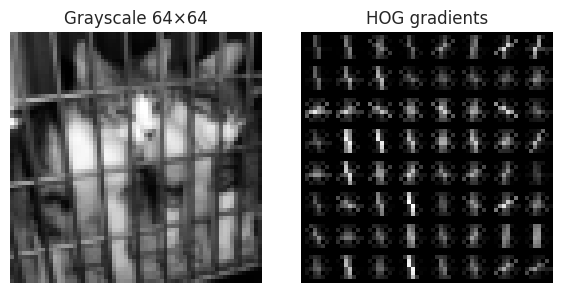

In [ ]:
t0 = time.time()
Htr, Hva, Hte = fe.hog_features(Gtr), fe.hog_features(Gva), fe.hog_features(Gte)
FEATS["hog"] = (Htr, Hva, Hte)
print(f"HOG dimension: {Htr.shape[1]} per image (extracted in {time.time()-t0:.0f}s)")

hog_vals = [1.0] if FAST_DEBUG else [1.0, 10.0]
hsvm, BEST["hog_svm"], t, tune_hog = tm.tune_on_val(
    lambda C: make_pipeline(StandardScaler(), SVC(kernel="rbf", C=C, gamma="scale")),
    hog_vals, Htr, ytr, Hva, yva)
m = register_ml("HOG + SVM", hsvm, "hog", t)
display(tune_hog.rename(columns={"param": "C"}))

# visualise what HOG sees
from skimage.feature import hog as _hog
_, hog_img = _hog(Gtr[0], orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)
fig, ax = plt.subplots(1, 2, figsize=(6, 3))
ax[0].imshow(Gtr[0], cmap="gray"); ax[0].set_title("Grayscale 64×64"); ax[0].axis("off")
ax[1].imshow(hog_img, cmap="gray"); ax[1].set_title("HOG gradients"); ax[1].axis("off")
plt.tight_layout(); plt.show()

### Q40. HOG + SVM vs Raw Pixels + SVM

In [ ]:
cmp40 = pd.DataFrame({k: RES_VAL[k] for k in ["SVM - Raw Pixels", "HOG + SVM"]}).T[["accuracy", "precision", "recall", "f1", "roc_auc", "train_time_s"]].round(4)
display(cmp40)
winner = cmp40["accuracy"].idxmax()
md(f"**Q40:** **{winner}** performs better on validation "
   f"(HOG+SVM {RES_VAL['HOG + SVM']['accuracy']:.4f} vs raw+SVM {RES_VAL['SVM - Raw Pixels']['accuracy']:.4f}); "
   f"HOG uses {Htr.shape[1]:,} features instead of {Xtr_raw.shape[1]:,}.")

,accuracy,precision,recall,f1,roc_auc,train_time_s
SVM - Raw Pixels,0.6450,0.6399,0.6633,0.6514,0.7098,305.2817
HOG + SVM,0.7333,0.7389,0.7217,0.7302,0.8179,28.6375


**Q40:** **HOG + SVM** performs better on validation (HOG+SVM 0.7333 vs raw+SVM 0.6450); HOG uses 1,764 features instead of 12,288.

**Why HOG usually wins:** HOG describes **local edge directions** in small cells and normalises them over blocks, so it captures **shape and contour** (ears, snout, body outline) while being **robust to lighting / contrast changes** and small shifts. Raw pixels encode brightness and colour, which vary enormously for the same animal. HOG also compresses the image into a much smaller, more meaningful vector, reducing over-fitting. (It still cannot match a CNN because it is hand-crafted and fixed.)

### Q41. PCA — how much dimensionality reduction at 90 % / 95 % variance?

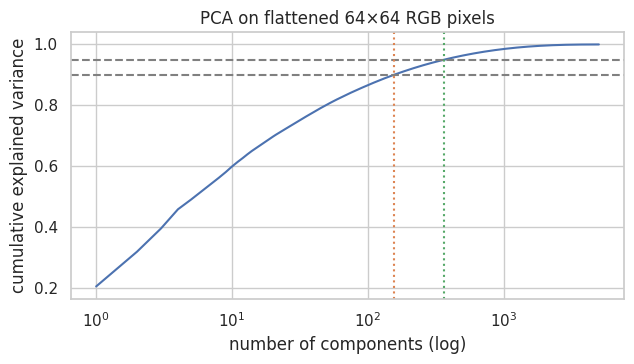

**Q41:** 90 % of the variance is kept with **155** components (a **98.7%** reduction from 12,288), and 95 % with **364** components (**97.0%** reduction). The first component alone explains 20.6% — mostly global brightness. PCA was fit on the training subset only (89s).

In [ ]:
from sklearn.decomposition import PCA
t0 = time.time()
pca = PCA(svd_solver="full", random_state=SEED).fit(Xtr_raw)         # fit on TRAIN only
pca_time = time.time() - t0
cum = np.cumsum(pca.explained_variance_ratio_)
n90 = int(np.searchsorted(cum, 0.90) + 1)
n95 = int(np.searchsorted(cum, 0.95) + 1)
d = Xtr_raw.shape[1]

plt.figure(figsize=(6.5, 3.8))
plt.plot(np.arange(1, len(cum) + 1), cum)
plt.axhline(0.90, ls="--", c="gray"); plt.axhline(0.95, ls="--", c="gray")
plt.axvline(n90, ls=":", c="C1"); plt.axvline(n95, ls=":", c="C2")
plt.xscale("log"); plt.xlabel("number of components (log)"); plt.ylabel("cumulative explained variance")
plt.title("PCA on flattened 64×64 RGB pixels"); plt.tight_layout(); plt.show()
md(f"**Q41:** 90 % of the variance is kept with **{n90}** components (a **{(1-n90/d)*100:.1f}%** reduction from {d:,}), "
   f"and 95 % with **{n95}** components (**{(1-n95/d)*100:.1f}%** reduction). "
   f"The first component alone explains {pca.explained_variance_ratio_[0]*100:.1f}% — mostly global brightness. PCA was fit on the training subset only ({pca_time:.0f}s).")

# transform once (all components), then slice
Ztr, Zva, Zte = pca.transform(Xtr_raw), pca.transform(Xva_raw), pca.transform(Xte_raw)
FEATS["pca90"] = (Ztr[:, :n90], Zva[:, :n90], Zte[:, :n90])
FEATS["pca95"] = (Ztr[:, :n95], Zva[:, :n95], Zte[:, :n95])
del Ztr, Zva, Zte

### Q42. Classifier on PCA features vs original features

In [ ]:
for feat, label in [("pca90", "PCA90 + SVM"), ("pca95", "PCA95 + SVM")]:
    mdl, t = tm.fit_timed(make_pipeline(StandardScaler(), SVC(kernel="rbf", C=BEST["svm"], gamma="scale")), FEATS[feat][0], ytr)
    register_ml(label, mdl, feat, t + pca_time)       # include the PCA fitting cost
mdl, t = tm.fit_timed(KNeighborsClassifier(n_neighbors=BEST["knn"], n_jobs=-1), FEATS["pca95"][0], ytr)
register_ml("PCA95 + KNN", mdl, "pca95", t + pca_time)

names42 = ["SVM - Raw Pixels", "PCA90 + SVM", "PCA95 + SVM", "KNN", "PCA95 + KNN"]
cmp42 = pd.DataFrame({k: RES_VAL[k] for k in names42}).T[["accuracy", "precision", "recall", "f1", "roc_auc", "train_time_s"]].round(4)
display(cmp42)
md(f"**Q42:** with only **{n95}** features (instead of {d:,}) the SVM reaches **{RES_VAL['PCA95 + SVM']['accuracy']:.4f}** "
   f"vs **{RES_VAL['SVM - Raw Pixels']['accuracy']:.4f}** on raw pixels. "
   + (f"The change in accuracy is {(RES_VAL['PCA95 + SVM']['accuracy']-RES_VAL['SVM - Raw Pixels']['accuracy'])*100:+.2f} points. ") +
   "PCA removes redundant, noisy directions and shortens model fitting/prediction, "
   "but it is **linear and unsupervised** – it keeps directions of high variance (often lighting) that are not necessarily the most discriminative ones, so it cannot add the shape information a CNN learns.")

,accuracy,precision,recall,f1,roc_auc,train_time_s
SVM - Raw Pixels,0.6450,0.6399,0.6633,0.6514,0.7098,305.2817
PCA90 + SVM,0.6367,0.6480,0.5983,0.6222,0.6926,92.5418
PCA95 + SVM,0.6150,0.6237,0.5800,0.6010,0.6673,93.9988
KNN,0.5917,0.5899,0.6017,0.5957,0.6234,0.0239
PCA95 + KNN,0.6008,0.5868,0.6817,0.6307,0.6371,89.0764


**Q42:** with only **364** features (instead of 12,288) the SVM reaches **0.6150** vs **0.6450** on raw pixels. The change in accuracy is -3.00 points. PCA removes redundant, noisy directions and shortens model fitting/prediction, but it is **linear and unsupervised** – it keeps directions of high variance (often lighting) that are not necessarily the most discriminative ones, so it cannot add the shape information a CNN learns.

---
# Phase 7 — Deep Learning with CNN

In [ ]:
%%writefile src/train_cnn.py
"""CNN / transfer-learning builders, augmentation, training helpers."""
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# three architectures for Q46 (A = the brief's baseline)
CNN_VARIANTS = {
    "cnn_A_baseline": dict(filters=(32, 64, 128), kernel=3, convs_per_block=1, batch_norm=False,
                           gap=False, dense=128, dropout=0.4),
    "cnn_B_deep_bn": dict(filters=(32, 64, 128, 256), kernel=3, convs_per_block=2, batch_norm=True,
                          gap=True, dense=128, dropout=0.5),
    "cnn_C_k5_light": dict(filters=(16, 32, 64), kernel=5, convs_per_block=1, batch_norm=False,
                           gap=False, dense=64, dropout=0.3),
}


def set_seed(seed=42):
    keras.utils.set_random_seed(seed)


def build_cnn(cfg, name, img_size=128):
    """Input -> Rescaling(1/255) -> [Conv(+BN)+ReLU]xN -> MaxPool ... -> Flatten/GAP -> Dense -> Dropout -> sigmoid."""
    inputs = layers.Input((img_size, img_size, 3), name="image")
    x = layers.Rescaling(1.0 / 255.0, name="rescale_0_1")(inputs)       # normalisation lives INSIDE the model
    for f in cfg["filters"]:
        for _ in range(cfg.get("convs_per_block", 1)):
            x = layers.Conv2D(f, cfg["kernel"], padding="same", use_bias=not cfg["batch_norm"])(x)
            if cfg["batch_norm"]:
                x = layers.BatchNormalization()(x)
            x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.GlobalAveragePooling2D()(x) if cfg["gap"] else layers.Flatten()(x)
    x = layers.Dense(cfg["dense"], activation="relu")(x)
    x = layers.Dropout(cfg["dropout"])(x)
    out = layers.Dense(1, activation="sigmoid", name="p_dog")(x)
    return keras.Model(inputs, out, name=name)


def random_shear(images, max_shear=0.15):
    """Random horizontal shear of a float32 batch (N,H,W,3), reflect-filled."""
    n = tf.shape(images)[0]
    h = tf.cast(tf.shape(images)[1], tf.float32)
    s = tf.random.uniform([n], -max_shear, max_shear)
    ones, zeros = tf.ones([n]), tf.zeros([n])
    transforms = tf.stack([ones, s, -s * h / 2.0, zeros, ones, zeros, zeros, zeros], axis=1)
    return tf.raw_ops.ImageProjectiveTransformV3(
        images=images, transforms=transforms, output_shape=tf.shape(images)[1:3],
        fill_value=0.0, interpolation="BILINEAR", fill_mode="REFLECT")


def build_augmentation(rotation=0.08, zoom=0.2, shift=0.1, shear=0.15, flip=True):
    """Returns f(batch)->augmented batch (flip, rotation, zoom, shift, shear). Use on TRAIN data only."""
    seq = [layers.RandomFlip("horizontal")] if flip else []
    seq += [layers.RandomRotation(rotation, fill_mode="reflect"),
            layers.RandomZoom(zoom, fill_mode="reflect"),
            layers.RandomTranslation(shift, shift, fill_mode="reflect")]
    pipe = keras.Sequential(seq)

    def augment(x):
        x = pipe(x, training=True)
        return random_shear(x, shear) if shear else x
    return augment


def build_transfer_model(img_size=224, pretrained=True, dropout=0.2):
    """MobileNetV2 backbone (frozen) + GAP + Dropout + sigmoid head. Preprocessing is inside the model."""
    base = keras.applications.MobileNetV2(input_shape=(img_size, img_size, 3), include_top=False,
                                          weights="imagenet" if pretrained else None)
    base.trainable = False
    inputs = layers.Input((img_size, img_size, 3), name="image")
    x = layers.Rescaling(1.0 / 127.5, offset=-1.0, name="rescale_-1_1")(inputs)   # MobileNetV2 expects [-1, 1]
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(1, activation="sigmoid", name="p_dog")(x)
    return keras.Model(inputs, out, name="mobilenetv2_transfer"), base


def unfreeze_top(base, n_layers=30):
    """Fine-tuning: unfreeze the last n layers of the backbone (BatchNorm layers stay frozen)."""
    base.trainable = True
    for layer in base.layers[:-n_layers]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False


def get_callbacks(name, models_dir, logs_dir, patience=4):
    models_dir, logs_dir = Path(models_dir), Path(logs_dir)
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
            keras.callbacks.ModelCheckpoint(str(models_dir / f"{name}.keras"), monitor="val_loss", save_best_only=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7),
            keras.callbacks.CSVLogger(str(logs_dir / f"{name}_history.csv"))]


def train_model(model, train_ds, val_ds, name, epochs, lr, models_dir, logs_dir, patience=4):
    """Compile + fit with EarlyStopping / ModelCheckpoint. Returns (history DataFrame, seconds, checkpoint path)."""
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])
    t0 = time.perf_counter()
    h = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                  callbacks=get_callbacks(name, models_dir, logs_dir, patience), verbose=2)
    secs = time.perf_counter() - t0
    hist = pd.DataFrame(h.history)
    hist.insert(0, "epoch", np.arange(1, len(hist) + 1))
    return hist, secs, Path(models_dir) / f"{name}.keras"


def predict_scores(model, ds):
    return model.predict(ds, verbose=0).ravel()


def n_trainable(model):
    return int(sum(np.prod(w.shape) for w in model.trainable_weights))


def parameter_table(model):
    """Per-layer parameter counts with the textbook formula for Conv2D / Dense / BatchNorm."""
    rows = []
    for l in model.layers:
        p = int(sum(np.prod(w.shape) for w in l.trainable_weights))
        if p == 0 and not l.weights:
            continue
        f = ""
        if isinstance(l, layers.Conv2D):
            kh, kw = l.kernel_size
            cin, cout = l.kernel.shape[2], l.filters
            f = f"({kh}x{kw}x{cin}) x {cout}" + (f" + {cout} bias" if l.use_bias else " (no bias, BN follows)")
        elif isinstance(l, layers.Dense):
            f = f"{l.kernel.shape[0]} x {l.units} + {l.units} bias"
        elif isinstance(l, layers.BatchNormalization):
            f = f"2 x {l.gamma.shape[0]} (gamma, beta)"
        rows.append({"layer": l.name, "type": l.__class__.__name__, "trainable_params": p, "formula": f})
    return pd.DataFrame(rows)


def plot_history(hist, title=""):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    for a, (tr, va, lab) in zip(ax, [("accuracy", "val_accuracy", "Accuracy"), ("loss", "val_loss", "Loss")]):
        a.plot(hist["epoch"], hist[tr], marker="o", label="train")
        a.plot(hist["epoch"], hist[va], marker="o", label="validation")
        a.set_xlabel("epoch"); a.set_ylabel(lab); a.set_title(f"{title} – {lab}"); a.legend()
    plt.tight_layout(); plt.show()


def interpret_history(hist):
    """Auto-generated reading of the learning curves (markdown string)."""
    hist = hist.reset_index(drop=True)
    b = hist.loc[hist["val_loss"].idxmin()]
    last = hist.iloc[-1]
    gap_b, gap_l = b["accuracy"] - b["val_accuracy"], last["accuracy"] - last["val_accuracy"]
    if b["val_accuracy"] < 0.75 and b["accuracy"] < 0.80:
        verdict = "**Underfitting** – both curves are still low; the model needs more capacity, more epochs or better features."
    elif gap_l > 0.08 or last["val_loss"] > 1.10 * b["val_loss"]:
        verdict = "**Overfitting** – training accuracy keeps rising while validation loss stalls or increases (large train–val gap)."
    else:
        verdict = "**Good fit** – validation tracks training closely with a small gap; no strong over- or under-fitting."
    return (f"- Best epoch (lowest val-loss): **{int(b['epoch'])}** of {len(hist)}.\n"
            f"- At best epoch: train acc **{b['accuracy']:.3f}**, val acc **{b['val_accuracy']:.3f}** (gap {gap_b:+.3f}); val loss {b['val_loss']:.3f}.\n"
            f"- At last epoch: train acc {last['accuracy']:.3f}, val acc {last['val_accuracy']:.3f} (gap {gap_l:+.3f}); val loss {last['val_loss']:.3f}.\n"
            f"- Verdict: {verdict}")

Writing src/train_cnn.py


In [ ]:
import tensorflow as tf
import src.train_cnn as tc
importlib.reload(tc)
tc.set_seed(SEED)
gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow", tf.__version__, "| GPUs:", gpus if gpus else "NONE – training will be slow (Runtime → Change runtime type → GPU)")

def make_ds(df, size, shuffle=False, augment=None):
    return pp.make_dataset(df["clean_path"].tolist(), df["y"].values, size, BATCH, shuffle=shuffle, seed=SEED, augment=augment)

cnn_ds = {"train": make_ds(train_df, CNN_IMG, shuffle=True), "val": make_ds(val_df, CNN_IMG), "test": make_ds(test_df, CNN_IMG)}
y_val_all, y_test_all = val_df["y"].values, test_df["y"].values

def register_dl(name, model, path, img_size, train_time, val_ds, hist):
    """Validation metrics for a trained Keras model (test set is NOT used here)."""
    score = tc.predict_scores(model, val_ds)
    pred = (score >= 0.5).astype(int)
    m = tm.compute_metrics(y_val_all, pred, score)
    m["train_time_s"] = train_time
    RES_VAL[name], VAL_PRED[name] = m, (pred, score)
    REG[name] = dict(kind="dl", path=str(path), img_size=img_size, train_time=train_time,
                     params=model.count_params(), trainable=tc.n_trainable(model), history=hist)
    return m

HIST = {}

TensorFlow 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Q43. Design the CNN — purpose of each layer
The baseline (variant **A**) follows the architecture suggested in the brief:

| Layer | Configuration | Purpose |
|---|---|---|
| `Rescaling` | ×1/255 | Normalises pixels to 0–1 *inside* the model (identical at train & inference time) |
| `Conv2D` + `ReLU` | 32 / 64 / 128 filters, 3×3 | Learn **local filters**: edges and colour blobs → textures (fur) → parts (ears, eyes, snout). ReLU adds non-linearity so stacked layers can model complex functions |
| `MaxPooling2D` | 2×2 | Halves height and width, keeps the strongest response → **translation tolerance**, fewer parameters, larger receptive field |
| `Flatten` | – | Turns the final feature maps into one vector for the classifier |
| `Dense` + `ReLU` | 128 units | Combines high-level features into a non-linear decision boundary |
| `Dropout` | 0.4 | Randomly switches off units while training → **regularisation** against over-fitting |
| `Dense(1)` + `sigmoid` | 1 unit | Outputs **P(Dog)** ∈ (0,1); trained with binary cross-entropy |

In [ ]:
model_A = tc.build_cnn(tc.CNN_VARIANTS["cnn_A_baseline"], "cnn_A_baseline", CNN_IMG)
model_A.summary()

Model: "cnn_A_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale_0_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_dog (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,287,809 (16.36 MB)

 Trainable params: 4,287,809 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

### Q44. Number of trainable parameters

In [ ]:
pt = tc.parameter_table(model_A)
display(pt)
total_tr = tc.n_trainable(model_A)
assert total_tr == pt["trainable_params"].sum()
md(f"**Q44:** the baseline CNN has **{total_tr:,}** trainable parameters (`model.count_params()` = {model_A.count_params():,}, none non-trainable). "
   "Formulas: Conv2D = (k·k·C_in + 1)·C_out; Dense = (inputs + 1)·units; pooling / dropout / flatten have **0** parameters. "
   f"Note that the first Dense layer alone holds {int(pt.loc[pt['type']=='Dense','trainable_params'].iloc[0]):,} weights ({100*pt.loc[pt['type']=='Dense','trainable_params'].iloc[0]/total_tr:.0f}% of the model) because Flatten feeds it the whole feature map.")

,layer,type,trainable_params,formula
0,conv2d,Conv2D,896,(3x3x3) x 32 + 32 bias
1,conv2d_1,Conv2D,18496,(3x3x32) x 64 + 64 bias
2,conv2d_2,Conv2D,73856,(3x3x64) x 128 + 128 bias
3,dense,Dense,4194432,32768 x 128 + 128 bias
4,p_dog,Dense,129,128 x 1 + 1 bias


**Q44:** the baseline CNN has **4,287,809** trainable parameters (`model.count_params()` = 4,287,809, none non-trainable). Formulas: Conv2D = (k·k·C_in + 1)·C_out; Dense = (inputs + 1)·units; pooling / dropout / flatten have **0** parameters. Note that the first Dense layer alone holds 4,194,432 weights (98% of the model) because Flatten feeds it the whole feature map.

### Q45. Train the CNN and read the learning curves

Epoch 1/15
274/274 - 59s - 215ms/step - accuracy: 0.6453 - auc: 0.7050 - loss: 0.6249 - val_accuracy: 0.7292 - val_auc: 0.8125 - val_loss: 0.5370 - learning_rate: 0.0010
Epoch 2/15
274/274 - 37s - 134ms/step - accuracy: 0.7487 - auc: 0.8289 - loss: 0.5099 - val_accuracy: 0.7802 - val_auc: 0.8684 - val_loss: 0.4704 - learning_rate: 0.0010
Epoch 3/15
274/274 - 33s - 122ms/step - accuracy: 0.7970 - auc: 0.8799 - loss: 0.4381 - val_accuracy: 0.8104 - val_auc: 0.8930 - val_loss: 0.4204 - learning_rate: 0.0010
Epoch 4/15
274/274 - 41s - 148ms/step - accuracy: 0.8216 - auc: 0.9018 - loss: 0.3975 - val_accuracy: 0.8112 - val_auc: 0.8903 - val_loss: 0.4315 - learning_rate: 0.0010
Epoch 5/15
274/274 - 32s - 118ms/step - accuracy: 0.8555 - auc: 0.9328 - loss: 0.3319 - val_accuracy: 0.8379 - val_auc: 0.9150 - val_loss: 0.3824 - learning_rate: 0.0010
Epoch 6/15
274/274 - 41s - 150ms/step - accuracy: 0.8690 - auc: 0.9446 - loss: 0.3024 - val_accuracy: 0.8315 - val_auc: 0.9097 - val_loss: 0.4106 - le

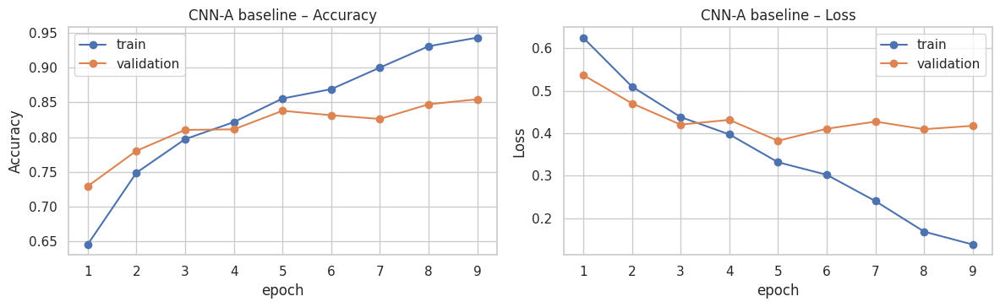

**Q45 – what do the curves tell us?**
- Best epoch (lowest val-loss): **5** of 9.
- At best epoch: train acc **0.855**, val acc **0.838** (gap +0.018); val loss 0.382.
- At last epoch: train acc 0.943, val acc 0.854 (gap +0.089); val loss 0.418.
- Verdict: **Overfitting** – training accuracy keeps rising while validation loss stalls or increases (large train–val gap).
- Validation metrics of the restored best model: accuracy **0.8379**, F1 0.8302, ROC-AUC 0.9151 (trained in 5.9 min).

In [ ]:
hist, secs, path = tc.train_model(model_A, cnn_ds["train"], cnn_ds["val"], "cnn_A_baseline", EPOCHS_CNN, 1e-3, MODELS_DIR, LOGS_DIR)
HIST["cnn_A_baseline"] = hist
m = register_dl("cnn_A_baseline", model_A, path, CNN_IMG, secs, cnn_ds["val"], hist)
tc.plot_history(hist, "CNN-A baseline")
md("**Q45 – what do the curves tell us?**\n" + tc.interpret_history(hist) +
   f"\n- Validation metrics of the restored best model: accuracy **{m['accuracy']:.4f}**, F1 {m['f1']:.4f}, ROC-AUC {m['roc_auc']:.4f} (trained in {secs/60:.1f} min).")

### Q46. Compare at least three CNN architectures

| Variant | Conv layers | Kernel | Extras | Dropout | Head |
|---|---|---|---|---|---|
| **A baseline** | 3 (32-64-128) | 3×3 | – | 0.4 | Flatten + Dense 128 |
| **B deep + BN** | 8 (4 blocks × 2 convs, 32-…-256) | 3×3 | BatchNorm | 0.5 | GlobalAvgPool + Dense 128 |
| **C light, big kernel** | 3 (16-32-64) | **5×5** | – | 0.3 | Flatten + Dense 64 |

Epoch 1/15
274/274 - 91s - 332ms/step - accuracy: 0.6803 - auc: 0.7391 - loss: 0.6047 - val_accuracy: 0.5000 - val_auc: 0.6000 - val_loss: 0.8385 - learning_rate: 0.0010
Epoch 2/15
274/274 - 38s - 138ms/step - accuracy: 0.7404 - auc: 0.8137 - loss: 0.5295 - val_accuracy: 0.6450 - val_auc: 0.8072 - val_loss: 0.8114 - learning_rate: 0.0010
Epoch 3/15
274/274 - 36s - 131ms/step - accuracy: 0.7971 - auc: 0.8721 - loss: 0.4516 - val_accuracy: 0.7057 - val_auc: 0.8694 - val_loss: 0.5374 - learning_rate: 0.0010
Epoch 4/15
274/274 - 46s - 166ms/step - accuracy: 0.8435 - auc: 0.9163 - loss: 0.3695 - val_accuracy: 0.7521 - val_auc: 0.8670 - val_loss: 0.5778 - learning_rate: 0.0010
Epoch 5/15
274/274 - 38s - 138ms/step - accuracy: 0.8693 - auc: 0.9394 - loss: 0.3157 - val_accuracy: 0.6544 - val_auc: 0.9122 - val_loss: 0.6611 - learning_rate: 0.0010
Epoch 6/15
274/274 - 37s - 135ms/step - accuracy: 0.9074 - auc: 0.9676 - loss: 0.2306 - val_accuracy: 0.8440 - val_auc: 0.9600 - val_loss: 0.3516 - le

,params,epochs run,best epoch,train acc,val acc,val loss,val F1,val AUC,train-val gap,time (s)
architecture,,,,,,,,,,
cnn_A_baseline,4287809,9,5,0.8555,0.8379,0.3824,0.8302,0.9151,0.0176,352.9593
cnn_B_deep_bn,1208161,11,7,0.9233,0.8817,0.2695,0.8752,0.9626,0.0416,476.7521
cnn_C_k5_light,1114017,11,7,0.8591,0.8104,0.4290,0.8221,0.8952,0.0487,432.0575


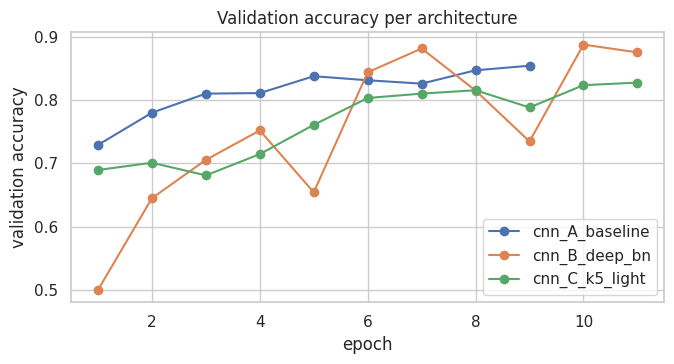

**Q46:** the best architecture on the **validation set** is **cnn_B_deep_bn** (val acc **0.8817**, 1,208,161 parameters). Depth + BatchNorm + global pooling usually generalise best with the fewest parameters per unit of accuracy, while the flatten-based variants hold most of their weights in one Dense layer and over-fit sooner. The selection used validation data only.

In [ ]:
for name in ["cnn_B_deep_bn", "cnn_C_k5_light"]:
    tc.set_seed(SEED)
    mdl = tc.build_cnn(tc.CNN_VARIANTS[name], name, CNN_IMG)
    h, secs, path = tc.train_model(mdl, cnn_ds["train"], cnn_ds["val"], name, EPOCHS_CNN, 1e-3, MODELS_DIR, LOGS_DIR)
    HIST[name] = h
    register_dl(name, mdl, path, CNN_IMG, secs, cnn_ds["val"], h)
    del mdl

rows = []
for name in tc.CNN_VARIANTS:
    h = HIST[name].reset_index(drop=True); b = h.loc[h["val_loss"].idxmin()]
    rows.append({"architecture": name, "params": REG[name]["params"], "epochs run": len(h), "best epoch": int(b["epoch"]),
                 "train acc": b["accuracy"], "val acc": RES_VAL[name]["accuracy"], "val loss": b["val_loss"],
                 "val F1": RES_VAL[name]["f1"], "val AUC": RES_VAL[name]["roc_auc"],
                 "train-val gap": b["accuracy"] - b["val_accuracy"], "time (s)": RES_VAL[name]["train_time_s"]})
cmp46 = pd.DataFrame(rows).set_index("architecture")
display(cmp46.round(4))
cmp46.to_csv(REPORTS_DIR / "cnn_architecture_comparison_val.csv")

plt.figure(figsize=(7, 3.8))
for name in tc.CNN_VARIANTS:
    plt.plot(HIST[name]["epoch"], HIST[name]["val_accuracy"], marker="o", label=name)
plt.xlabel("epoch"); plt.ylabel("validation accuracy"); plt.title("Validation accuracy per architecture"); plt.legend(); plt.tight_layout(); plt.show()

best_cnn = max(tc.CNN_VARIANTS, key=lambda n: (RES_VAL[n]["accuracy"], -cmp46.loc[n, "val loss"]))
md(f"**Q46:** the best architecture on the **validation set** is **{best_cnn}** (val acc **{RES_VAL[best_cnn]['accuracy']:.4f}**, "
   f"{REG[best_cnn]['params']:,} parameters). Depth + BatchNorm + global pooling usually generalise best with the fewest parameters per unit of accuracy, "
   "while the flatten-based variants hold most of their weights in one Dense layer and over-fit sooner. The selection used validation data only.")

---
# Phase 8 — Data Augmentation & Transfer Learning

### Q47. Augmentation: rotation, flip, zoom, shift, shear — before vs after

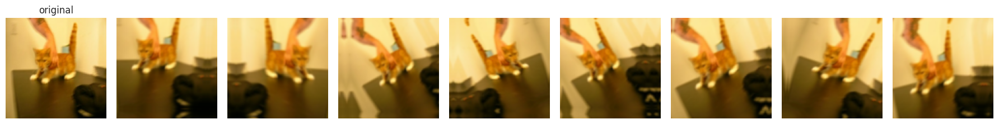

Epoch 1/25
274/274 - 146s - 533ms/step - accuracy: 0.6124 - auc: 0.6565 - loss: 0.6607 - val_accuracy: 0.5171 - val_auc: 0.5730 - val_loss: 0.7076 - learning_rate: 0.0010
Epoch 2/25
274/274 - 128s - 467ms/step - accuracy: 0.6600 - auc: 0.7150 - loss: 0.6200 - val_accuracy: 0.5841 - val_auc: 0.6867 - val_loss: 0.7058 - learning_rate: 0.0010
Epoch 3/25
274/274 - 129s - 470ms/step - accuracy: 0.6876 - auc: 0.7474 - loss: 0.5942 - val_accuracy: 0.5614 - val_auc: 0.7395 - val_loss: 0.7435 - learning_rate: 0.0010
Epoch 4/25
274/274 - 129s - 472ms/step - accuracy: 0.7065 - auc: 0.7734 - loss: 0.5735 - val_accuracy: 0.7126 - val_auc: 0.7900 - val_loss: 0.5599 - learning_rate: 0.0010
Epoch 5/25
274/274 - 127s - 465ms/step - accuracy: 0.7404 - auc: 0.8107 - loss: 0.5329 - val_accuracy: 0.6581 - val_auc: 0.7746 - val_loss: 0.7981 - learning_rate: 0.0010
Epoch 6/25
274/274 - 133s - 485ms/step - accuracy: 0.7655 - auc: 0.8396 - loss: 0.4975 - val_accuracy: 0.7382 - val_auc: 0.8444 - val_loss: 0.535

In [ ]:
augment = tc.build_augmentation(rotation=0.08, zoom=0.2, shift=0.1, shear=0.15, flip=True)

# visualise 8 random augmentations of one training image
img = next(iter(make_ds(train_df.head(1), CNN_IMG)))[0]            # (1,H,W,3) float 0-255
aug_batch = augment(tf.repeat(img, 8, axis=0)).numpy().clip(0, 255).astype("uint8")
fig, axes = plt.subplots(1, 9, figsize=(18, 2.3))
axes[0].imshow(img[0].numpy().astype("uint8")); axes[0].set_title("original")
for a_, im in zip(axes[1:], aug_batch):
    a_.imshow(im)
for a_ in axes: a_.axis("off")
plt.tight_layout(); plt.show()

# retrain the BEST architecture with augmentation on the training stream only
name_aug = f"{best_cnn}_aug"
tc.set_seed(SEED)
model_aug = tc.build_cnn(tc.CNN_VARIANTS[best_cnn], name_aug, CNN_IMG)
train_aug_ds = make_ds(train_df, CNN_IMG, shuffle=True, augment=augment)
h_aug, secs, path = tc.train_model(model_aug, train_aug_ds, cnn_ds["val"], name_aug, EPOCHS_AUG, 1e-3, MODELS_DIR, LOGS_DIR, patience=6)
HIST[name_aug] = h_aug
m_aug = register_dl(name_aug, model_aug, path, CNN_IMG, secs, cnn_ds["val"], h_aug)

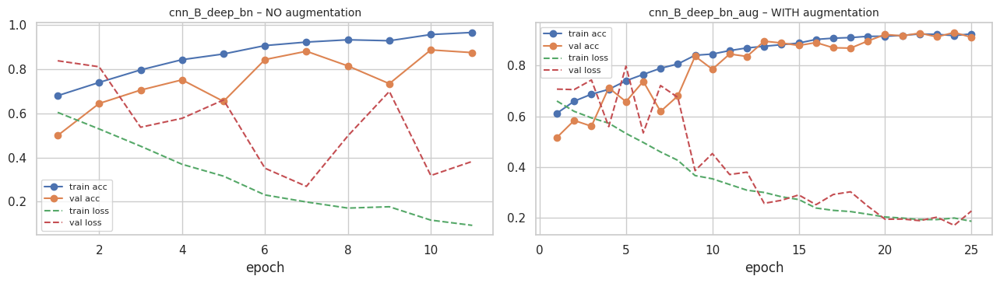

,accuracy,precision,recall,f1,roc_auc,train-val acc gap,best val loss,train_time_s
before augmentation,0.8817,0.9261,0.8297,0.8752,0.9626,0.0416,0.2695,476.7521
after augmentation,0.9308,0.9334,0.9279,0.9307,0.9824,-0.0124,0.1708,3323.2916


**Q47 – analysis**
- Validation accuracy: **0.8817 → 0.9308** (+4.91 points); best validation loss 0.269 → 0.171.
- Train–validation accuracy gap at the best epoch: +0.042 → -0.012 (augmentation **narrowed the gap** – less over-fitting).
- Augmentation makes every epoch show a slightly different version of each photo, so the network cannot memorise exact pixels and must learn pose/position-tolerant features. Training accuracy is typically *lower and slower to rise* with augmentation – that is expected and healthy; the benefit shows in validation loss and the smaller gap. Augmentation is applied **only to training batches**; validation/test images are untouched.

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharey=False)
for a_, (h, ttl) in zip(ax, [(HIST[best_cnn], f"{best_cnn} – NO augmentation"), (h_aug, f"{name_aug} – WITH augmentation")]):
    a_.plot(h["epoch"], h["accuracy"], marker="o", label="train acc"); a_.plot(h["epoch"], h["val_accuracy"], marker="o", label="val acc")
    a_.plot(h["epoch"], h["loss"], ls="--", label="train loss"); a_.plot(h["epoch"], h["val_loss"], ls="--", label="val loss")
    a_.set_title(ttl, fontsize=10); a_.set_xlabel("epoch"); a_.legend(fontsize=8)
plt.tight_layout(); plt.show()

def gap_at_best(h):
    h = h.reset_index(drop=True); b = h.loc[h["val_loss"].idxmin()]
    return b["accuracy"] - b["val_accuracy"], b["val_loss"]
g0, vl0 = gap_at_best(HIST[best_cnn]); g1, vl1 = gap_at_best(h_aug)
cmp47 = pd.DataFrame({"before augmentation": RES_VAL[best_cnn], "after augmentation": m_aug}).T
cmp47["train-val acc gap"] = [g0, g1]; cmp47["best val loss"] = [vl0, vl1]
display(cmp47[["accuracy", "precision", "recall", "f1", "roc_auc", "train-val acc gap", "best val loss", "train_time_s"]].round(4))
md("**Q47 – analysis**\n"
   f"- Validation accuracy: **{RES_VAL[best_cnn]['accuracy']:.4f} → {m_aug['accuracy']:.4f}** ({(m_aug['accuracy']-RES_VAL[best_cnn]['accuracy'])*100:+.2f} points); "
   f"best validation loss {vl0:.3f} → {vl1:.3f}.\n"
   f"- Train–validation accuracy gap at the best epoch: {g0:+.3f} → {g1:+.3f} "
   + ("(augmentation **narrowed the gap** – less over-fitting).\n" if g1 < g0 else "(the gap did not shrink – the model was not over-fitting much, or needs more epochs to benefit).\n") +
   "- Augmentation makes every epoch show a slightly different version of each photo, so the network cannot memorise exact pixels and must learn pose/position-tolerant features. "
   "Training accuracy is typically *lower and slower to rise* with augmentation – that is expected and healthy; the benefit shows in validation loss and the smaller gap. "
   "Augmentation is applied **only to training batches**; validation/test images are untouched.")

### Q48. Transfer learning with MobileNetV2 (frozen head → fine-tuning)
1. Load **MobileNetV2** pretrained on ImageNet (`include_top=False`) and **freeze** it.
2. Train only the new head (GlobalAveragePooling → Dropout → sigmoid) with a normal learning rate.
3. **Unfreeze the top 30 layers** (BatchNorm stays frozen) and fine-tune with a **very small learning rate (1e-5)**.

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
MobileNetV2 total params: 2,259,265 | trainable (head only): 1,281 | pretrained weights: True
Epoch 1/5
274/274 - 358s - 1s/step - accuracy: 0.9424 - auc: 0.9884 - loss: 0.1457 - val_accuracy: 0.9864 - val_auc: 0.9978 - val_loss: 0.0501 - learning_rate: 0.0010
Epoch 2/5
274/274 - 346s - 1s/step - accuracy: 0.9769 - auc: 0.9973 - loss: 0.0638 - val_accuracy: 0.9880 - val_auc: 0.9982 - val_loss: 0.0406 - learning_rate: 0.0010
Epoch 3/5
274/274 - 365s - 1s/step - accuracy: 0.9791 - auc: 0.9976 - loss: 0.0577 - val_accuracy: 0.9888 - val_auc: 0.9983 - val_loss: 0.0380 - learning_rate: 0.0010
Epoch 4/5
274/274 - 354s - 1s/step - accuracy: 0.9795 - auc: 0.9977 - loss: 0.0548 - val_accuracy: 0.9877 - val_auc: 0.9982 - val_loss: 0.0374 - learning_rate: 0.0010
Epoch 5/5
274/274 - 348s - 1s/step - accuracy: 0.9805 - auc: 0.9980 - loss: 0.0531 - val_accuracy: 0.9899 - val_auc: 0.9984 - val_loss: 0.0369 - learning_rate: 0.0010
trainable parameters a

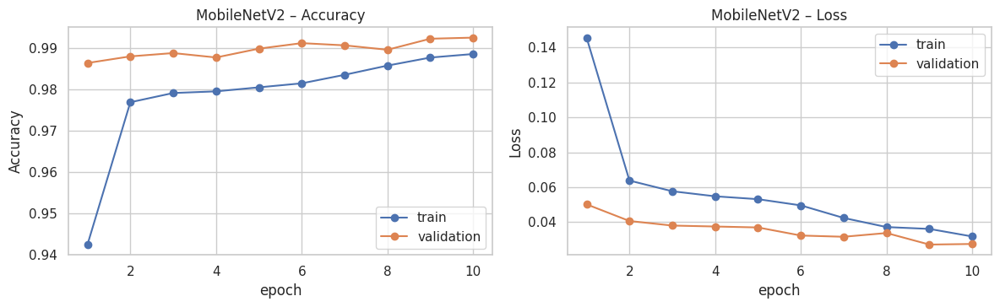

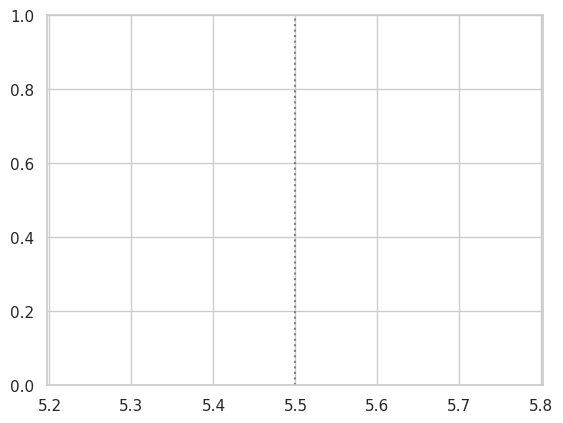

In [ ]:
tl_ds = {"train": make_ds(train_df, TL_IMG, shuffle=True, augment=tc.build_augmentation(rotation=0.05, zoom=0.15, shift=0.08, shear=0.0)),
         "val": make_ds(val_df, TL_IMG), "test": make_ds(test_df, TL_IMG)}

tc.set_seed(SEED)
tl_model, tl_base = tc.build_transfer_model(TL_IMG, pretrained=PRETRAINED)
print(f"MobileNetV2 total params: {tl_model.count_params():,} | trainable (head only): {tc.n_trainable(tl_model):,} | pretrained weights: {PRETRAINED}")

# Phase A – frozen backbone
hA, secsA, pathA = tc.train_model(tl_model, tl_ds["train"], tl_ds["val"], "mobilenetv2_head", EPOCHS_TL_HEAD, 1e-3, MODELS_DIR, LOGS_DIR, patience=3)
register_dl("MobileNetV2 (frozen)", tl_model, pathA, TL_IMG, secsA, tl_ds["val"], hA)

# Phase B – fine-tune the top layers with a small learning rate
tc.unfreeze_top(tl_base, 30)
print("trainable parameters after unfreezing:", f"{tc.n_trainable(tl_model):,}")
hB, secsB, pathB = tc.train_model(tl_model, tl_ds["train"], tl_ds["val"], "mobilenetv2_finetune", EPOCHS_TL_FT, 1e-5, MODELS_DIR, LOGS_DIR, patience=3)
register_dl("MobileNetV2 (fine-tuned)", tl_model, pathB, TL_IMG, secsA + secsB, tl_ds["val"], hB)

hTL = pd.concat([hA.assign(phase="head"), hB.assign(epoch=hB["epoch"] + len(hA), phase="fine-tune")], ignore_index=True)
HIST["MobileNetV2"] = hTL
tc.plot_history(hTL, "MobileNetV2")
plt.axvline(len(hA) + 0.5, c="gray", ls=":")

In [ ]:
names48 = [best_cnn, name_aug, "MobileNetV2 (frozen)", "MobileNetV2 (fine-tuned)"]
cmp48 = pd.DataFrame({k: RES_VAL[k] for k in names48}).T[["accuracy", "precision", "recall", "f1", "roc_auc", "train_time_s"]]
cmp48["params"] = [REG[k]["params"] for k in names48]
cmp48["trainable (at end)"] = [REG[k]["trainable"] for k in names48]
display(cmp48.round(4))
bt = "MobileNetV2 (fine-tuned)" if RES_VAL["MobileNetV2 (fine-tuned)"]["accuracy"] >= RES_VAL["MobileNetV2 (frozen)"]["accuracy"] else "MobileNetV2 (frozen)"
md(f"**Q48:** transfer learning reaches **{RES_VAL[bt]['accuracy']:.4f}** validation accuracy ({bt}) vs **{RES_VAL[best_cnn]['accuracy']:.4f}** for the best from-scratch CNN "
   f"and **{RES_VAL[name_aug]['accuracy']:.4f}** with augmentation. The pretrained backbone already encodes edges, textures and animal parts learnt from 1.2 M ImageNet images "
   "(which include many dog and cat breeds), so only a tiny head must be learned – it converges in a few epochs and needs far less data than training from scratch. "
   + ("Fine-tuning the top layers gave an additional gain." if bt.endswith("(fine-tuned)") else "Fine-tuning did not improve validation accuracy, so the frozen-backbone model is preferred.")
   + (" *(Note: this run used random weights – set `PRETRAINED=True`.)*" if not PRETRAINED else ""))

,accuracy,precision,recall,f1,roc_auc,train_time_s,params,trainable (at end)
cnn_B_deep_bn,0.8817,0.9261,0.8297,0.8752,0.9626,476.7521,1208161,1206241
cnn_B_deep_bn_aug,0.9308,0.9334,0.9279,0.9307,0.9824,3323.2916,1208161,1206241
MobileNetV2 (frozen),0.9899,0.9904,0.9893,0.9899,0.9985,1771.2042,2259265,1281
MobileNetV2 (fine-tuned),0.9923,0.9909,0.9936,0.9923,0.9990,3447.5613,2259265,1512001


**Q48:** transfer learning reaches **0.9923** validation accuracy (MobileNetV2 (fine-tuned)) vs **0.8817** for the best from-scratch CNN and **0.9308** with augmentation. The pretrained backbone already encodes edges, textures and animal parts learnt from 1.2 M ImageNet images (which include many dog and cat breeds), so only a tiny head must be learned – it converges in a few epochs and needs far less data than training from scratch. Fine-tuning the top layers gave an additional gain.

---
# Q49 — Final model selection & detailed evaluation

**Step 1 – model selection on the *validation* set only.** Only after the selection is final do we score all models once on the untouched test set.

In [ ]:
val_all = pd.DataFrame(RES_VAL).T[["accuracy", "precision", "recall", "f1", "roc_auc", "train_time_s"]].astype(float)
dl_names = [n for n, r in REG.items() if r["kind"] == "dl"]
final_name = max(dl_names, key=lambda n: (RES_VAL[n]["f1"], RES_VAL[n]["roc_auc"]))      # deployed model = best DL model on VALIDATION F1
display(val_all.sort_values("f1", ascending=False).round(4))
md(f"✅ **Selected final (deployed) model: `{final_name}`** — highest validation F1 among the deep-learning models "
   f"(F1 {RES_VAL[final_name]['f1']:.4f}, ROC-AUC {RES_VAL[final_name]['roc_auc']:.4f}). The test set has not been used so far.")

,accuracy,precision,recall,f1,roc_auc,train_time_s
MobileNetV2 (fine-tuned),0.9923,0.9909,0.9936,0.9923,0.9990,3447.5613
MobileNetV2 (frozen),0.9899,0.9904,0.9893,0.9899,0.9985,1771.2042
cnn_B_deep_bn_aug,0.9308,0.9334,0.9279,0.9307,0.9824,3323.2916
cnn_B_deep_bn,0.8817,0.9261,0.8297,0.8752,0.9626,476.7521
cnn_A_baseline,0.8379,0.8719,0.7923,0.8302,0.9151,352.9593
cnn_C_k5_light,0.8104,0.7744,0.8761,0.8221,0.8952,432.0575
HOG + SVM,0.7333,0.7389,0.7217,0.7302,0.8179,28.6375
SVM - Raw Pixels,0.6450,0.6399,0.6633,0.6514,0.7098,305.2817
SVM (gray),0.6350,0.6266,0.6683,0.6468,0.6813,71.7838
PCA95 + KNN,0.6008,0.5868,0.6817,0.6307,0.6371,89.0764


✅ **Selected final (deployed) model: `MobileNetV2 (fine-tuned)`** — highest validation F1 among the deep-learning models (F1 0.9923, ROC-AUC 0.9990). The test set has not been used so far.

**Step 2 – one-time evaluation of every model on the test set** (same test files for all models).

In [ ]:
from sklearn.metrics import roc_curve
RES_TEST, TEST_PRED = {}, {}
ML_SAVE_DIR = DATA_DIR / "ml_models"      # classical models are large (KNN/RF store data) → local disk; only the best is copied to models/
ML_SAVE_DIR.mkdir(parents=True, exist_ok=True)

def time_ml(model, X):
    t0 = time.perf_counter(); pred = model.predict(X); score = tm.get_scores(model, X)
    return pred, score, (time.perf_counter() - t0) / len(X) * 1000

for name, r in REG.items():
    if r["kind"] == "ml":
        X = FEATS[r["feat"]][2]
        pred, score, ms = time_ml(r["model"], X)
        size = tm.save_ml_model(r["model"], ML_SAVE_DIR / f"{re.sub(r'[^A-Za-z0-9]+', '_', name)}.joblib")
        params = np.nan
    else:
        mdl = tf.keras.models.load_model(r["path"], compile=False)
        ds = tl_ds["test"] if r["img_size"] == TL_IMG else cnn_ds["test"]
        score = tc.predict_scores(mdl, ds); pred = (score >= 0.5).astype(int)
        xb, _ = next(iter(ds)); mdl.predict(xb, verbose=0)
        t0 = time.perf_counter()
        for _ in range(3): mdl.predict(xb, verbose=0)
        ms = (time.perf_counter() - t0) / 3 / len(xb) * 1000
        size = os.path.getsize(r["path"]) / 1e6; params = r["params"]
        del mdl
    m = tm.compute_metrics(y_test_all, pred, score)
    m.update(train_time_s=r["train_time"], inference_ms_per_img=ms, model_size_MB=size, params=params)
    RES_TEST[name], TEST_PRED[name] = m, (pred, score)

test_all = pd.DataFrame(RES_TEST).T
rows12 = [("Majority / Random Baseline", "Majority baseline"), ("Logistic Regression", "Logistic Regression"), ("KNN", "KNN"),
          ("SVM - Raw Pixels", "SVM - Raw Pixels"), ("Random Forest", "Random Forest"), ("HOG + SVM", "HOG + SVM"),
          ("PCA + Classifier", "PCA95 + SVM"), ("Custom CNN", best_cnn), ("CNN + Augmentation", name_aug),
          ("Transfer Learning", "MobileNetV2 (fine-tuned)")]
final_cols = ["accuracy", "precision", "recall", "f1", "roc_auc", "train_time_s", "inference_ms_per_img", "model_size_MB"]
final_tab = pd.DataFrame({lab: test_all.loc[key, final_cols] for lab, key in rows12}).T.astype(float)
final_tab.index.name = "Approach"
display(final_tab.round(4).style.highlight_max(subset=["accuracy", "precision", "recall", "f1", "roc_auc"], color="#c6efce").format("{:.4f}"))
final_tab.round(4).to_csv(REPORTS_DIR / "final_model_comparison.csv")
final_tab.round(4).to_excel(REPORTS_DIR / "final_model_comparison.xlsx")
test_all.round(4).to_csv(REPORTS_DIR / "all_experiments_test_results.csv")
with open(REPORTS_DIR / "val_results.json", "w") as f: json.dump(RES_VAL, f, indent=2, default=float)
print("Saved: reports/final_model_comparison.csv/.xlsx (Section 12 table), all_experiments_test_results.csv")

,accuracy,precision,recall,f1,roc_auc,train_time_s,inference_ms_per_img,model_size_MB
Approach,,,,,,,,
Majority / Random Baseline,0.4999,0.0000,0.0000,0.0000,0.5000,0.0011,0.0001,0.0004
Logistic Regression,0.6075,0.6052,0.6188,0.6119,0.6472,10.9278,0.3366,0.3616
KNN,0.5677,0.5701,0.5515,0.5607,0.6024,0.0239,8.0041,77.6253
SVM - Raw Pixels,0.6521,0.6438,0.6813,0.6620,0.7045,305.2817,197.2790,234.7406
Random Forest,0.6344,0.6571,0.5627,0.6063,0.6949,92.4478,0.1332,3.7244
HOG + SVM,0.7330,0.7328,0.7336,0.7332,0.8200,28.6375,17.3578,35.1228
PCA + Classifier,0.6259,0.6321,0.6028,0.6171,0.6839,93.9988,4.0250,7.8187
Custom CNN,0.8852,0.9339,0.8292,0.8784,0.9625,476.7521,1.4321,14.6261
CNN + Augmentation,0.9372,0.9366,0.9381,0.9373,0.9844,3323.2916,1.7667,14.6262


Saved: reports/final_model_comparison.csv/.xlsx (Section 12 table), all_experiments_test_results.csv


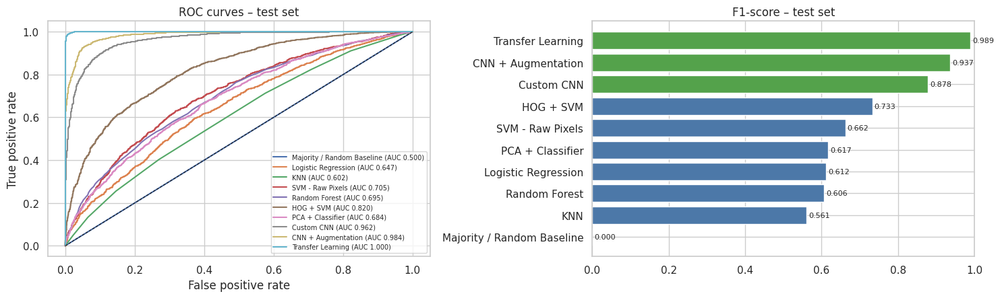

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
for lab, key in rows12:
    _, s = TEST_PRED[key]
    fpr, tpr, _ = roc_curve(y_test_all, s)
    ax[0].plot(fpr, tpr, label=f"{lab} (AUC {RES_TEST[key]['roc_auc']:.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=.8); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[0].set_title("ROC curves – test set"); ax[0].legend(fontsize=7, loc="lower right")
f1s = final_tab["f1"].sort_values()
ax[1].barh(f1s.index, f1s.values, color=["#4C78A8" if i < 7 else "#54A24B" for i in range(len(f1s))])
ax[1].set_title("F1-score – test set"); ax[1].set_xlim(0, 1)
for i, v in enumerate(f1s.values): ax[1].text(v + .005, i, f"{v:.3f}", va="center", fontsize=8)
plt.tight_layout(); plt.show()

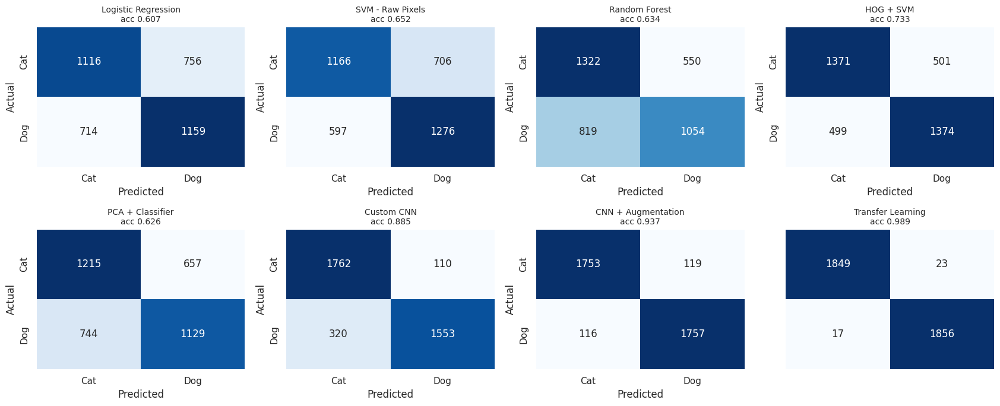

**Interpretation (test set)**
- Best classical model (chosen on validation): **HOG + SVM** → test accuracy **0.7330**, F1 0.7332.
- Best custom CNN: **cnn_B_deep_bn** → 0.8852; with augmentation **0.9372**.
- Transfer learning (fine-tuned MobileNetV2) → **0.9893** accuracy, ROC-AUC 0.9997.
- Gap between best classical and deployed model: **+25.6 accuracy points**.
- Cost of that gain: inference 2.4 ms/img and 21.7 MB for `MobileNetV2 (fine-tuned)`, vs 17.36 ms/img and 35.1 MB for HOG + SVM (classical inference excludes feature extraction time).
- Why the deep models win: convolutional filters learn position-tolerant shape/texture features directly from data; transfer learning adds features from ImageNet; raw-pixel models cannot (see Q37).

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, (lab, key) in zip(axes.ravel(), [r for r in rows12 if r[0] not in ("Majority / Random Baseline", "KNN")]):
    plot_cm(ax, y_test_all, TEST_PRED[key][0], f"{lab}\nacc {RES_TEST[key]['accuracy']:.3f}")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

best_ml = max([n for n, r in REG.items() if r["kind"] == "ml" and n != "Majority baseline"], key=lambda n: RES_VAL[n]["f1"])
best_ml_file = ML_SAVE_DIR / f"{re.sub(r'[^A-Za-z0-9]+', '_', best_ml)}.joblib"
shutil.copy(best_ml_file, MODELS_DIR / best_ml_file.name)
md("**Interpretation (test set)**\n"
   f"- Best classical model (chosen on validation): **{best_ml}** → test accuracy **{RES_TEST[best_ml]['accuracy']:.4f}**, F1 {RES_TEST[best_ml]['f1']:.4f}.\n"
   f"- Best custom CNN: **{best_cnn}** → {RES_TEST[best_cnn]['accuracy']:.4f}; with augmentation **{RES_TEST[name_aug]['accuracy']:.4f}**.\n"
   f"- Transfer learning (fine-tuned MobileNetV2) → **{RES_TEST['MobileNetV2 (fine-tuned)']['accuracy']:.4f}** accuracy, ROC-AUC {RES_TEST['MobileNetV2 (fine-tuned)']['roc_auc']:.4f}.\n"
   f"- Gap between best classical and deployed model: **{(RES_TEST[final_name]['accuracy']-RES_TEST[best_ml]['accuracy'])*100:+.1f} accuracy points**.\n"
   f"- Cost of that gain: inference {RES_TEST[final_name]['inference_ms_per_img']:.1f} ms/img and {RES_TEST[final_name]['model_size_MB']:.1f} MB for `{final_name}`, vs {RES_TEST[best_ml]['inference_ms_per_img']:.2f} ms/img and {RES_TEST[best_ml]['model_size_MB']:.1f} MB for {best_ml} "
   "(classical inference excludes feature extraction time).\n"
   "- Why the deep models win: convolutional filters learn position-tolerant shape/texture features directly from data; transfer learning adds features from ImageNet; raw-pixel models cannot (see Q37).")

**Step 3 – sample predictions from the deployed model** (random test images; green = correct, red = wrong)

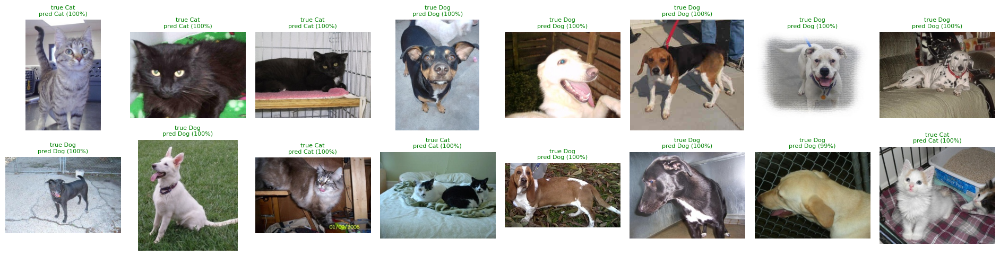

In [ ]:
fm = tf.keras.models.load_model(REG[final_name]["path"], compile=False)
f_pred, f_score = TEST_PRED[final_name]
rs = np.random.default_rng(SEED).choice(len(test_df), 16, replace=False)
fig, axes = plt.subplots(2, 8, figsize=(19, 5))
for ax, i in zip(axes.ravel(), rs):
    with Image.open(test_df.at[i, "clean_path"]) as im: ax.imshow(im.convert("RGB"))
    ok_ = f_pred[i] == y_test_all[i]
    ax.set_title(f"true {pp.CLASS_NAMES[y_test_all[i]]}\npred {pp.CLASS_NAMES[f_pred[i]]} ({max(f_score[i],1-f_score[i])*100:.0f}%)",
                 fontsize=8, color="green" if ok_ else "red"); ax.axis("off")
plt.tight_layout(); plt.show()

---
# 13. Error Analysis — what does the deployed model get wrong?

In [ ]:
ea = test_df.copy()
ea["p_dog"] = f_score; ea["pred"] = f_pred; ea["correct"] = ea["pred"] == ea["y"]
ea["confidence"] = np.maximum(ea["p_dog"], 1 - ea["p_dog"])
ea["error_type"] = np.where(ea["correct"], "correct", np.where(ea["y"] == 1, "Dog→Cat (false negative)", "Cat→Dog (false positive)"))

def image_props(path):
    with Image.open(path) as im:
        g = np.asarray(im.convert("L").resize((128, 128)), dtype="float32")
    lap = 4 * g[1:-1, 1:-1] - g[:-2, 1:-1] - g[2:, 1:-1] - g[1:-1, :-2] - g[1:-1, 2:]
    return g.mean(), g.std(), lap.var()
props = np.array([image_props(p) for p in ea["clean_path"]])
ea["brightness"], ea["contrast"], ea["sharpness"] = props.T
ea["min_side"] = ea[["width", "height"]].min(axis=1)
ea["aspect"] = ea["width"] / ea["height"]
ea["file_kb"] = ea["file_size"] / 1024

n_err = int((~ea["correct"]).sum())
print(f"{n_err} errors out of {len(ea)} test images ({n_err/len(ea)*100:.2f}%)")
display(ea["error_type"].value_counts().to_frame("count"))
rep = pd.DataFrame({"class": pp.CLASS_NAMES,
                    "precision": [ (ea[(ea.pred==c)].y==c).mean() for c in (0,1)],
                    "recall": [ (ea[(ea.y==c)].pred==c).mean() for c in (0,1)]}).round(4)
display(rep)

40 errors out of 3745 test images (1.07%)


,count
error_type,
correct,3705
Cat→Dog (false positive),23
Dog→Cat (false negative),17


,class,precision,recall
0,Cat,0.9909,0.9877
1,Dog,0.9878,0.9909


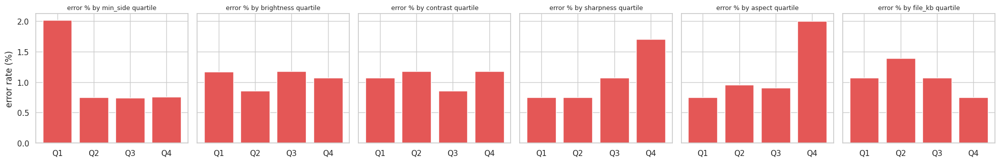

**Which kinds of images are hardest?** (quartile Q1 = lowest values, Q4 = highest)
- **min_side**: highest error in quartile Q1 (2.0%) vs lowest 0.7%
- **aspect**: highest error in quartile Q4 (2.0%) vs lowest 0.7%
- **sharpness**: highest error in quartile Q4 (1.7%) vs lowest 0.7%
- **file_kb**: highest error in quartile Q2 (1.4%) vs lowest 0.7%
- Error split: 17 dogs predicted as cats and 23 cats predicted as dogs.

In [ ]:
factors = ["min_side", "brightness", "contrast", "sharpness", "aspect", "file_kb"]
fig, axes = plt.subplots(1, len(factors), figsize=(20, 3.4), sharey=True)
worst = []
for ax, f in zip(axes, factors):
    q = pd.qcut(ea[f], 4, duplicates="drop")
    er = ea.groupby(q, observed=True)["correct"].apply(lambda s: 100 * (1 - s.mean()))
    ax.bar(range(len(er)), er.values, color="#E45756"); ax.set_xticks(range(len(er)))
    ax.set_xticklabels(["Q%d" % (i + 1) for i in range(len(er))]); ax.set_title(f"error % by {f} quartile", fontsize=9)
    worst.append((f, er.max() / max(er.min(), 0.05), int(er.values.argmax()) + 1, er.max(), er.min()))
axes[0].set_ylabel("error rate (%)"); plt.tight_layout(); plt.show()
worst.sort(key=lambda t: -t[1])
md("**Which kinds of images are hardest?** (quartile Q1 = lowest values, Q4 = highest)\n" +
   "\n".join(f"- **{f}**: highest error in quartile Q{q} ({hi:.1f}%) vs lowest {lo:.1f}%" for f, _, q, hi, lo in worst[:4]) +
   f"\n- Error split: {int((ea.error_type=='Dog→Cat (false negative)').sum())} dogs predicted as cats and {int((ea.error_type=='Cat→Dog (false positive)').sum())} cats predicted as dogs.")

Most CONFIDENT mistakes (often label noise or genuinely ambiguous photos):


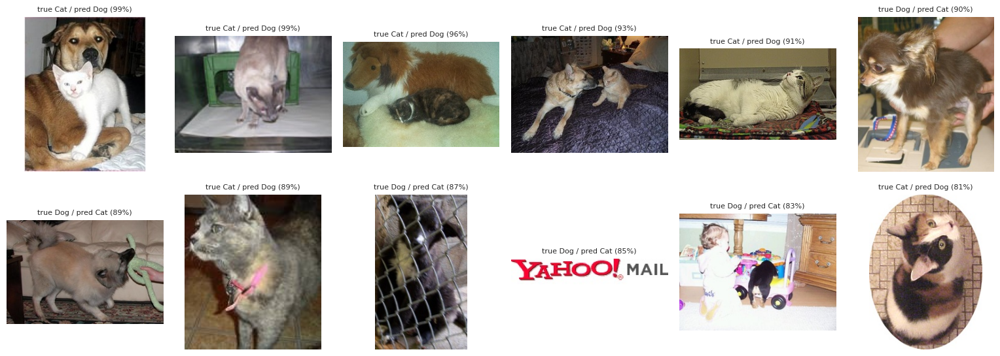

Most UNCERTAIN predictions (probability near 0.5):


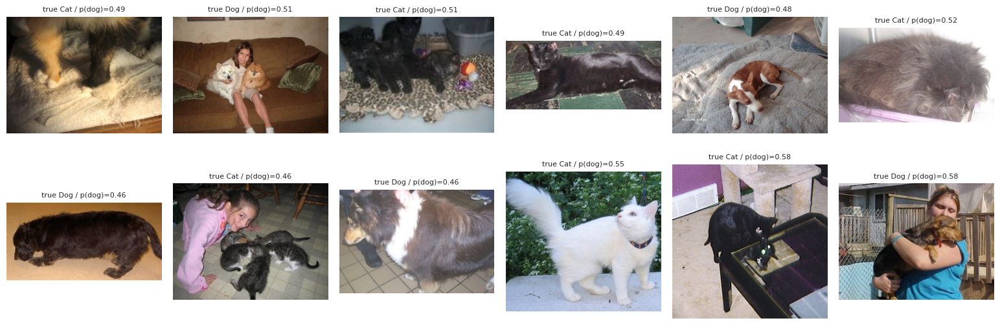

In [ ]:
wrong = ea[~ea["correct"]].sort_values("confidence", ascending=False)
print("Most CONFIDENT mistakes (often label noise or genuinely ambiguous photos):")
show_images(wrong.head(12)["clean_path"].tolist(),
            [f"true {pp.CLASS_NAMES[y]} / pred {pp.CLASS_NAMES[p]} ({c*100:.0f}%)" for y, p, c in zip(wrong.head(12)["y"], wrong.head(12)["pred"], wrong.head(12)["confidence"])], ncols=6, size=2.6)
border = ea.assign(d=(ea["p_dog"] - 0.5).abs()).sort_values("d").head(12)
print("Most UNCERTAIN predictions (probability near 0.5):")
show_images(border["clean_path"].tolist(),
            [f"true {pp.CLASS_NAMES[y]} / p(dog)={p:.2f}" for y, p in zip(border["y"], border["p_dog"])], ncols=6, size=2.6)
wrong[["clean_path", "path", "label", "p_dog", "confidence", "error_type"]].to_csv(REPORTS_DIR / "misclassified_test_images.csv", index=False)

**How to read the grids above (verify each hypothesis by looking at the images):**
* *Wrong label / ambiguous ground truth* – images in the "confident mistakes" grid that actually show the predicted class are dataset label noise, not model failures.
* *Multiple animals or people dominating the frame* – the model may respond to the wrong subject.
* *Partial, occluded or tiny animals; unusual poses (backs, paws, sleeping curls)* – little face information to use.
* *Drawings, cartoons, toys, or non-pet photos* – outside the training distribution.
* *Low resolution / blur / extreme brightness* – see the quartile bars: if error rises in the lowest sharpness/min-side quartile, image quality is a driver.
**Possible improvements:** clean mislabelled images, higher input resolution, stronger augmentation, a bigger backbone (EfficientNet / ResNet50), test-time augmentation, and a confidence threshold with an "uncertain" state (implemented in the app).

---
# Phase 9 — Final Deployment (Q50)

### Q50. End-to-end application
Flow: **Upload image → validate file → preprocess → load trained model → predict probability → Cat/Dog label → display result (+ history)**.

`src/predict.py` re-uses `data_cleaning.to_rgb` / `cap_size` (the same functions used to build the cleaned training set) and the same `tf.image.resize` call as the training pipeline, and the model itself contains its `Rescaling` layer – so inference preprocessing is **identical** to training.

In [ ]:
%%writefile src/predict.py
"""Inference helpers: validate an uploaded image, preprocess exactly like training, predict."""
import io

import numpy as np
from PIL import Image

from src.data_cleaning import CLEAN_MAX_SIDE, cap_size, to_rgb

CLASS_NAMES = ["Cat", "Dog"]          # index 0 = Cat, 1 = Dog (probability output = P(Dog))
MAX_UPLOAD_MB = 10
MIN_SIDE = 32
_CACHE = {}


def load_trained_model(path):
    """Load the saved Keras model (no retraining). Cached per path."""
    import tensorflow as tf
    path = str(path)
    if path not in _CACHE:
        _CACHE[path] = tf.keras.models.load_model(path, compile=False)
    return _CACHE[path]


def open_uploaded_image(file_like, max_mb=MAX_UPLOAD_MB):
    """Validate an upload; returns a fully decoded PIL image or raises ValueError with a friendly message."""
    data = file_like.read() if hasattr(file_like, "read") else bytes(file_like)
    if not data:
        raise ValueError("The uploaded file is empty.")
    if len(data) > max_mb * 1024 * 1024:
        raise ValueError(f"File is larger than {max_mb} MB.")
    try:
        with Image.open(io.BytesIO(data)) as im:
            im.verify()
        im = Image.open(io.BytesIO(data))
        im.load()
    except Exception:
        raise ValueError("This file is not a valid / readable image (try JPG, PNG, WEBP, BMP or GIF).")
    if min(im.size) < MIN_SIDE:
        raise ValueError(f"Image is too small ({im.width}x{im.height}); the shorter side must be at least {MIN_SIDE}px.")
    return im


def preprocess_image(im, img_size):
    """PIL image -> float32 batch (1, img_size, img_size, 3) in [0, 255] (the model rescales internally)."""
    import tensorflow as tf
    rgb = cap_size(to_rgb(im), CLEAN_MAX_SIDE)
    arr = np.asarray(rgb, dtype=np.float32)
    x = tf.image.resize(arr[None, ...], (img_size, img_size), antialias=True)
    return x.numpy()


def predict_image(model, im, threshold=0.5, min_confidence=0.0):
    """Return label, P(Dog), P(Cat), confidence and an 'uncertain' flag."""
    img_size = int(model.input_shape[1])
    p_dog = float(model.predict(preprocess_image(im, img_size), verbose=0)[0, 0])
    label = CLASS_NAMES[int(p_dog >= threshold)]
    confidence = p_dog if label == "Dog" else 1.0 - p_dog
    return {"label": label, "prob_dog": p_dog, "prob_cat": 1.0 - p_dog,
            "confidence": confidence, "uncertain": confidence < min_confidence}

Writing src/predict.py


In [ ]:
%%writefile app/app.py
"""Streamlit app – Cat vs Dog classifier.  Run:  streamlit run app/app.py"""
import os
import sys
from pathlib import Path

import pandas as pd
import streamlit as st

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT))
from src.predict import load_trained_model, open_uploaded_image, predict_image  # noqa: E402

MODEL_PATH = Path(os.environ.get("CATDOG_MODEL", ROOT / "models" / "final_model.keras"))

st.set_page_config(page_title="Cat vs Dog", page_icon="🐾", layout="centered")
st.title("🐱 Cat vs Dog 🐶")
st.caption("Upload a photo and the trained deep-learning model predicts the animal.")


@st.cache_resource(show_spinner="Loading model …")
def get_model(path):
    return load_trained_model(path)


if not MODEL_PATH.exists():
    st.error(f"Model file not found: `{MODEL_PATH}`. Train the model with the notebook first "
             "or set the CATDOG_MODEL environment variable.")
    st.stop()
model = get_model(str(MODEL_PATH))

min_conf = st.sidebar.slider("Minimum confidence before answering", 0.50, 0.99, 0.70, 0.01,
                             help="Below this the app reports 'Uncertain' instead of guessing.")
st.sidebar.write(f"Model: `{MODEL_PATH.name}`  \nInput size: {model.input_shape[1]}×{model.input_shape[2]}")
if "history" not in st.session_state:
    st.session_state.history = []

file = st.file_uploader("Choose an image", type=["jpg", "jpeg", "png", "webp", "bmp", "gif"])
if file is not None:
    try:
        image = open_uploaded_image(file)
    except ValueError as err:
        st.error(f"⚠️ {err}")
    else:
        st.image(image, caption=f"{file.name} ({image.width}×{image.height})", use_container_width=True)
        with st.spinner("Predicting …"):
            res = predict_image(model, image, min_confidence=min_conf)
        if res["uncertain"]:
            st.warning(f"🤔 **Uncertain** – best guess is {res['label']} but confidence is only {res['confidence']:.1%}.")
        elif res["label"] == "Cat":
            st.success(f"🐱 **Cat** – confidence {res['confidence']:.1%}")
        else:
            st.success(f"🐶 **Dog** – confidence {res['confidence']:.1%}")
        c1, c2 = st.columns(2)
        c1.metric("P(Cat)", f"{res['prob_cat']:.3f}")
        c2.metric("P(Dog)", f"{res['prob_dog']:.3f}")
        st.progress(float(res["prob_dog"]), text="probability of Dog")
        entry = {"file": file.name, "prediction": "Uncertain" if res["uncertain"] else res["label"],
                 "P(Dog)": round(res["prob_dog"], 4), "confidence": round(res["confidence"], 4)}
        if not st.session_state.history or st.session_state.history[-1] != entry:
            st.session_state.history.append(entry)

if st.session_state.history:
    st.subheader("Prediction history (this session)")
    st.dataframe(pd.DataFrame(st.session_state.history[::-1]), use_container_width=True)

Writing app/app.py


In [ ]:
importlib.invalidate_caches()
import py_compile, src.predict as pr
importlib.reload(pr)
py_compile.compile(str(APP_DIR / "app.py"), doraise=True)
print("✔ app/app.py compiles")

# ── save the selected model for deployment (no retraining needed afterwards) ──
FINAL_PATH = MODELS_DIR / "final_model.keras"
shutil.copy(REG[final_name]["path"], FINAL_PATH)
card = {"selected_model": final_name, "input_size": REG[final_name]["img_size"], "classes": pp.CLASS_NAMES,
        "output": "sigmoid = P(Dog); label Dog if >= 0.5", "preprocessing": "RGB, EXIF-rotate, longest side<=256, tf.image.resize(antialias) to input size, rescaling inside model",
        "test_metrics": {k: float(v) for k, v in RES_TEST[final_name].items() if k in ["accuracy", "precision", "recall", "f1", "roc_auc", "inference_ms_per_img", "model_size_MB"]},
        "seed": SEED, "trained_on_images": int(len(train_df))}
(MODELS_DIR / "model_card.json").write_text(json.dumps(card, indent=2))
print("Saved", FINAL_PATH, f"({os.path.getsize(FINAL_PATH)/1e6:.1f} MB) + model_card.json")

✔ app/app.py compiles
Saved /content/drive/MyDrive/Cat-Dog-Classification/models/final_model.keras (21.7 MB) + model_card.json


**Reproducibility test of the app pipeline.** Three *unseen* test images are sent through `src/predict.py` using their **original raw files** (not the cleaned copies) — exactly what a user upload looks like — and compared with the score obtained by the dataset pipeline.

      2799.jpg | app P(Dog)=0.0000 | notebook-pipeline P(Dog)=0.0000 | |diff|=0.0000
     10846.jpg | app P(Dog)=1.0000 | notebook-pipeline P(Dog)=1.0000 | |diff|=0.0000
     10289.jpg | app P(Dog)=0.9999 | notebook-pipeline P(Dog)=0.9999 | |diff|=0.0000


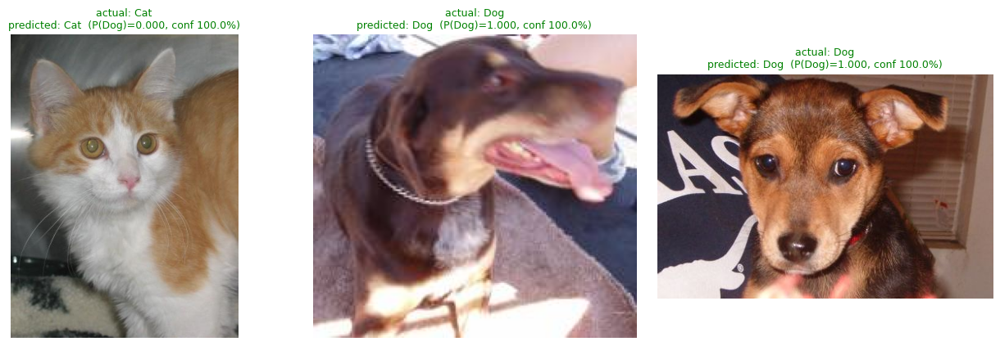

invalid upload (empty file) → handled: The uploaded file is empty.
invalid upload (random bytes) → handled: This file is not a valid / readable image (try JPG, PNG, WEBP, BMP or GIF).
invalid upload (text file) → handled: This file is not a valid / readable image (try JPG, PNG, WEBP, BMP or GIF).


In [ ]:
app_model = pr.load_trained_model(FINAL_PATH)
picks = test_df.sample(3, random_state=SEED + 7).index.tolist()
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
for ax, i in zip(axes, picks):
    raw_path = test_df.at[i, "path"]
    with open(raw_path, "rb") as fh:
        im = pr.open_uploaded_image(fh)
    r = pr.predict_image(app_model, im)
    ax.imshow(im); ax.axis("off")
    ax.set_title(f"actual: {test_df.at[i,'label']}\npredicted: {r['label']}  (P(Dog)={r['prob_dog']:.3f}, conf {r['confidence']:.1%})", fontsize=9,
                 color="green" if r["label"] == test_df.at[i, "label"] else "red")
    print(f"{Path(raw_path).name:>14} | app P(Dog)={r['prob_dog']:.4f} | notebook-pipeline P(Dog)={f_score[i]:.4f} | |diff|={abs(r['prob_dog']-f_score[i]):.4f}")
plt.tight_layout(); plt.show()

# graceful handling of bad uploads
import io
for label, blob in [("empty file", b""), ("random bytes", os.urandom(2048)), ("text file", b"hello world")]:
    try:
        pr.open_uploaded_image(io.BytesIO(blob))
    except ValueError as e:
        print(f"invalid upload ({label}) → handled: {e}")

### Run the app
**Locally:** `pip install -r requirements.txt` then `streamlit run app/app.py` (see README).
**From Colab (optional):** set `RUN_APP_IN_COLAB = True` below, run the cell, open the printed `loca.lt` URL and enter the printed IP as the tunnel password.

In [ ]:
RUN_APP_IN_COLAB = False
if RUN_APP_IN_COLAB and IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "streamlit"])
    env = dict(os.environ, CATDOG_MODEL=str(FINAL_PATH))
    subprocess.Popen([sys.executable, "-m", "streamlit", "run", "app/app.py", "--server.port", "8501", "--server.headless", "true"], env=env)
    time.sleep(8)
    print("Tunnel password (public IP):", subprocess.run("curl -s ipv4.icanhazip.com", shell=True, capture_output=True, text=True).stdout.strip())
    tun = subprocess.Popen(["npx", "--yes", "localtunnel", "--port", "8501"], stdout=subprocess.PIPE, text=True)
    print(tun.stdout.readline())
else:
    print("App launch skipped (RUN_APP_IN_COLAB=False). Run locally with: streamlit run app/app.py")

App launch skipped (RUN_APP_IN_COLAB=False). Run locally with: streamlit run app/app.py


---
# Deliverables: requirements, README and summary

In [ ]:
import importlib.metadata as im_
pkgs = ["numpy", "pandas", "matplotlib", "seaborn", "pillow", "scikit-learn", "scikit-image", "tensorflow", "streamlit", "joblib", "tqdm", "openpyxl", "gdown"]
lines = []
for p in pkgs:
    try:
        lines.append(f"{p}=={im_.version(p)}")
    except Exception:
        lines.append(p)
(PROJECT_DIR / "requirements.txt").write_text("\n".join(lines) + "\n")
print((PROJECT_DIR / "requirements.txt").read_text())

numpy==2.4.6
pandas==2.2.3
matplotlib==3.10.0
seaborn==0.13.2
pillow==11.3.0
scikit-learn==1.6.1
scikit-image==0.25.2
tensorflow==2.21.0
streamlit
joblib==1.6.0
tqdm==4.67.3
openpyxl==3.1.5
gdown==5.2.2



In [ ]:
%%writefile README.md
# Cat vs Dog Image Classification

End-to-end project: data audit → cleaning → preprocessing → classical ML (LR, KNN, SVM, RF, HOG, PCA) → CNNs → augmentation → transfer learning (MobileNetV2) → evaluation → Streamlit app.

## Structure
```
Cat-Dog-Classification/
├── Cat_vs_Dog_Capstone.ipynb   # all 50 questions with outputs
├── src/                        # reusable modules (data_cleaning, preprocessing, feature_engineering, train_ml, train_cnn, predict)
├── app/app.py                  # Streamlit application
├── models/                     # final_model.keras, CNN checkpoints, classical models (.joblib), model_card.json
├── reports/                    # metadata, splits.csv, clean_manifest.csv, final_model_comparison.csv/.xlsx, logs/
├── data/ (raw, cleaned, processed)   # created by the notebook (not versioned)
├── requirements.txt
└── README.md
```

## Reproduce the experiments
1. Python 3.10+ and `pip install -r requirements.txt` (a GPU is strongly recommended for the CNN / transfer-learning parts).
2. Put `Cats and Dogs Dataset for Image Classification.zip` next to the notebook (or set `DATASET_ZIP=/path/to/zip`).
3. Open the notebook and *Run all*. Use `FAST_DEBUG = True` for a quick dry run. The random seed is fixed (42) and the train/val/test file lists are saved in `reports/splits.csv`.

## Run the app locally
```bash
pip install -r requirements.txt
streamlit run app/app.py
```
The app loads `models/final_model.keras` (override with the `CATDOG_MODEL` environment variable), shows the uploaded image, the predicted class, P(Cat)/P(Dog), the confidence, an "Uncertain" state below a configurable confidence threshold, and a session prediction history. Invalid uploads (empty, non-image, too small, > 10 MB) are rejected with a message.

## Method notes
* Cleaning: unreadable files, label-conflict images, exact (MD5) and near (dHash) duplicates and tiny images are removed; all images are re-encoded as RGB JPEG (longest side ≤ 256).
* Split: stratified 70/15/15 with a fixed seed; no hash overlap between splits (asserted).
* Models are selected on the validation set; the test set is scored once at the end.
* Inference preprocessing is shared with training through `src/data_cleaning.py` and a `Rescaling` layer inside the model.

Writing README.md


---
# Final summary

In [ ]:
fin = RES_TEST[final_name]
base = RES_TEST[best_ml]
md(f"""## Results at a glance
* **Dataset:** {len(clean_df):,} clean images ({(clean_df['label']=='Cat').sum():,} cats / {(clean_df['label']=='Dog').sum():,} dogs) after removing {n0-len(clean_df):,} problematic files; split {len(train_df):,} / {len(val_df):,} / {len(test_df):,}.
* **Best classical model:** {best_ml} – test accuracy **{base['accuracy']:.3f}**, ROC-AUC {base['roc_auc']:.3f}.
* **Best custom CNN:** {best_cnn} – test accuracy {RES_TEST[best_cnn]['accuracy']:.3f}; with augmentation {RES_TEST[name_aug]['accuracy']:.3f}.
* **Deployed model:** `{final_name}` – test accuracy **{fin['accuracy']:.3f}**, precision {fin['precision']:.3f}, recall {fin['recall']:.3f}, F1 {fin['f1']:.3f}, ROC-AUC {fin['roc_auc']:.3f}; {fin['inference_ms_per_img']:.1f} ms/image, {fin['model_size_MB']:.1f} MB.
* **Errors:** {n_err} of {len(ea)} test images; see the error-analysis grids and `reports/misclassified_test_images.csv`.

## Limitations
* Single dataset with some label noise and several near-duplicates of the same animal; a group-aware split would be more rigorous.
* Classical models used a 64×64 subset of the training split for tractability; CNNs used all training images.
* Only two classes – anything that is neither cat nor dog is still forced into one of them (the confidence threshold in the app mitigates this).
* Single run per model (one seed); no confidence intervals.

## Future work
Compare EfficientNet / ResNet50 backbones, add Grad-CAM explanations, test-time augmentation, calibration analysis, an out-of-distribution "other" class, REST API (FastAPI) and Docker packaging, prediction logging for monitoring.
""")

## Results at a glance
* **Dataset:** 24,963 clean images (12,478 cats / 12,485 dogs) after removing 35 problematic files; split 17,474 / 3,744 / 3,745.
* **Best classical model:** HOG + SVM – test accuracy **0.733**, ROC-AUC 0.820.
* **Best custom CNN:** cnn_B_deep_bn – test accuracy 0.885; with augmentation 0.937.
* **Deployed model:** `MobileNetV2 (fine-tuned)` – test accuracy **0.989**, precision 0.988, recall 0.991, F1 0.989, ROC-AUC 1.000; 2.4 ms/image, 21.7 MB.
* **Errors:** 40 of 3745 test images; see the error-analysis grids and `reports/misclassified_test_images.csv`.

## Limitations
* Single dataset with some label noise and several near-duplicates of the same animal; a group-aware split would be more rigorous.
* Classical models used a 64×64 subset of the training split for tractability; CNNs used all training images.
* Only two classes – anything that is neither cat nor dog is still forced into one of them (the confidence threshold in the app mitigates this).
* Single run per model (one seed); no confidence intervals.

## Future work
Compare EfficientNet / ResNet50 backbones, add Grad-CAM explanations, test-time augmentation, calibration analysis, an out-of-distribution "other" class, REST API (FastAPI) and Docker packaging, prediction logging for monitoring.


In [ ]:
# bundle the deliverables (src, app, models, reports, README, requirements) for download – raw data excluded
bundle = str(PROJECT_DIR.parent / "capstone_deliverables.zip")
with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED) as zf:
    for item in ["src", "app", "models", "reports", "README.md", "requirements.txt"]:
        pth = PROJECT_DIR / item
        files_ = [pth] if pth.is_file() else [f for f in pth.rglob("*") if f.is_file() and "__pycache__" not in f.parts]
        for f in files_:
            zf.write(f, f.relative_to(PROJECT_DIR))
print("Bundle:", bundle, f"({os.path.getsize(bundle)/1e6:.1f} MB)")
if IN_COLAB:
    from google.colab import files
    files.download(bundle)

Bundle: /content/drive/MyDrive/capstone_deliverables.zip (159.2 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>